# Breaking GRPO: An Interactive Failure Lab for Reinforcement Learning with Verifiable Rewards

**NeurIPS 2026 Education Track Submission**

---

## The Concept We Teach

> **GRPO's structural failure modes, and the 2025 successor design space they produced (DAPO, DisCO, S-GRPO).**

Group Relative Policy Optimization (GRPO) is *new*: introduced in DeepSeekMath (Shao et al., 2024), scaled by DeepSeek-R1 (2025), and now the default algorithm for reinforcement learning with verifiable rewards (RLVR). Within a year, its documented failure modes had motivated **three NeurIPS 2025 papers**. That is the concept this lab teaches -- not RL fundamentals.

Every existing GRPO resource teaches *how* it works. None teach *when it breaks*. Yet it breaks in predictable, mechanical ways, and each break explains exactly why a specific successor method exists.

**The one sentence to take away:**

> *GRPO learns only when its samples contain informative contrasts -- and fails when the group or the verifier provides none.*

Three failures follow from that sentence, at three different structural levels. You will **cause each one with a slider**, then implement the fix and watch it disappear.

| Failure you will trigger | Level | Successor fix you will implement |
|---|---|---|
| Zero-gradient groups (all rollouts agree) | Group | DAPO **Dynamic Sampling** |
| Entropy collapse (clipping starves rare tokens) | Token | DAPO **Clip-Higher** |
| Length bias (short answers over-weighted) | Sequence | DAPO **Token-Level Loss** |
| Truncation reward cliff | Sequence | DAPO **Overlong Reward Shaping** |

## How this notebook is organized

```
Sec 1     PREREQUISITE SCAFFOLDING (~10 min) — SFT, policy gradients, PPO's 4 models, GRPO's 2
Sec 2-4   Build GRPO from scratch on KernelBench-framed micro-environments
Sec 5     >>> THE FAILURE LAB — the core of the tutorial <<<
Sec 6-7   The successors: DAPO implemented, DisCO & S-GRPO as frontier cards
Sec 8-10  When to use GRPO, exercises, references
```

**Note on Section 1.** SFT, policy gradients and PPO are well-established material. Section 1 covers them *only* as fast scaffolding so the failure analysis is legible to readers with no RL background. It is not the contribution -- skip it if you already know PPO.

## Learning Objectives

By the end you will be able to:

1. **Understand** why replacing PPO's critic with a group mean is simultaneously GRPO's efficiency win (4 models to 2) and the origin of its failure modes.
2. **Apply** the group-relative advantage by hand and implement a working GRPO update in ~30 lines of NumPy.
3. **Analyse** why symmetric ratio clipping is *asymmetric* in probability space, and why that starves exploration.
4. **Evaluate** when zero-gradient groups will dominate, predicting wasted compute from success rate and group size G.
5. **Create** the four DAPO fixes and verify each repairs its corresponding failure -- plus design a reward-hacking verifier and a defence against it.
6. **Evaluate** whether GRPO, DAPO, DisCO or S-GRPO suits a given task, using a readiness checklist.

## Prerequisites

Probability and expectations, gradients, the softmax function, and how an LLM samples tokens autoregressively. **No prior reinforcement learning knowledge assumed.**

**Time:** ~55 minutes &nbsp;|&nbsp; **Requirements:** Python 3.9+, NumPy, Matplotlib, ipywidgets (optional; static fallbacks included). Runs entirely on a laptop CPU -- no GPU, no LLM, no API keys.

> **Scope note on data.** To stay 100% CPU-runnable, the notebook uses **real KernelBench task specifications** (real Level-1 problem IDs and PyTorch reference ops) paired with **illustrative benchmark outcomes** reflecting patterns reported in KernelBench and Kevin. Per-kernel latency/speedup numbers are representative, *not* the product of live `nvcc` execution. See `data/kernelbench/README.md` for provenance and how to reproduce them on GPU hardware.

**Optional pre-reading:** `GRPO_PRIMER.md` gives a plain-language walkthrough of every concept here.

---
# Part I: Why RL and How GRPO Works

## Section 1: From Supervised Learning to Reinforcement Learning

### 1.1 What is Supervised Fine-Tuning (SFT) and Why Do We Need RL?

The standard paradigm for adapting pretrained LLMs to specific tasks is **Supervised Fine-Tuning (SFT)**. 

In SFT, we curate a dataset of demonstration pairs $(x, y)$, where $x$ is a task prompt (input specification) and $y = (y_1, y_2, \dots, y_T)$ is an expert demonstration target sequence.

**Concrete Example (KernelBench / GPU Kernel Optimization):**
- **Prompt $x$:** `"Write an optimized CUDA kernel for 2D matrix multiplication C = A @ B of size 1024x1024."`
- **Demonstration $y$:** A human-written CUDA implementation using a specific block size (`BLOCK_SIZE = 32`) and shared-memory tiling.

SFT trains the model to maximize the log-likelihood of each demonstrated token via standard cross-entropy loss:

$$
\mathcal{L}_{\text{SFT}}(\theta) = -\sum_{t=1}^{T} \log \pi_\theta(y_t \mid y_{<t}, x)
$$

SFT is purely **imitation learning** -- the model's objective is to mimic the exact token transitions of the demonstrator.

---

### The Three Fundamental Limitations of SFT

While SFT provides stable initial training, it faces severe structural ceilings when applied to reasoning and code generation:

1. **The Imitation Ceiling & Lack of Exploration:**
   The model can only ever be as capable as the demonstrations in its training set. If human demonstrations only contain basic shared-memory tiling, SFT cannot discover novel, hardware-specific optimization strategies (such as warp-level shuffle intrinsics `__shfl_down_sync`, register tiling, or tensor core instructions) that were absent from the training corpus.

2. **Rigid Token-Level Supervision vs. Equifinality:**
   In code and mathematics, there are often *dozens of completely distinct token sequences* that compute the exact same result (or achieve even higher throughput). SFT penalizes any valid token sequence that deviates from the single reference string, forcing the model to memorize arbitrary syntactic choices rather than learning underlying problem-solving logic.

3. **Distribution Shift & Error Compounding:**
   During autoregressive sampling at test time, if the model generates a single suboptimal token, it enters an unvisited state space where errors compound rapidly. Because SFT never trained the model to recover from its own mistakes, generation quickly degrades.

---

### Where Reinforcement Learning Enters: Exploration + Verifiable Outcomes

Reinforcement learning (RL) fundamentally shifts the supervisory signal from **how** to write (token imitation) to **what** is achieved (outcome evaluation).

Instead of forcing the model to match a reference string, RL allows the model to explore diverse candidate solutions, evaluates the final outcome using an automated **verifier**, and updates the policy weights to reinforce strategies that succeed:

| Dimension | Supervised Fine-Tuning (SFT) | Reinforcement Learning with Verifiable Rewards (RLVR) |
|---|---|---|
| **Learning Signal** | "Copy this exact token sequence" | "Your generated code compiled and ran 2.1x faster" |
| **Supervision Level** | Micro: every intermediate token | Macro: final execution / verification outcome |
| **Solution Diversity** | Constrained to demonstrated paths | Open: model can discover novel algorithmic strategies |
| **Supervision Cost** | Requires expensive human/expert traces | Requires an automated verifier + sampling compute |
| **Robustness** | Brittle to off-distribution prefixes | Self-correcting through trial and error |

> **Key Takeaway:** SFT teaches the model how to write code that *looks* right. RL teaches the model how to write code that *works* and *executes fast*.

### 1.2 The RL Loop in 30 Seconds & What is KernelBench?

#### What is KernelBench? (Stanford / ICML 2025)

**KernelBench** (Ouyang et al., ICML 2025; Scaling Intelligence Lab, Stanford) is the premier benchmark designed to evaluate and train LLMs on generating efficient, custom GPU kernels. It consists of 250 real-world PyTorch machine learning workloads across three levels of difficulty:
- **Level 1 (Foundational Operators):** Matrix multiplications, fast softmax, layer normalization, 1D/2D reductions.
- **Level 2 (Fused Operations):** Fused Bias-GeLU, Fused MatMul-Softmax, Attention blocks.
- **Level 3 (Architecture Blocks):** End-to-end Transformer layers and ConvNeXt blocks.

**How KernelBench Verifies Code:**
1. Given a PyTorch reference implementation (e.g., `torch.matmul(A, B) + bias`), the LLM generates a candidate CUDA/Triton kernel.
2. The verification harness compiles the kernel with `nvcc`. If compilation fails, **Reward = 0.0**.
3. It executes the kernel against randomized test inputs and checks numerical correctness using `torch.allclose(out_cuda, out_torch, atol=1e-3)`. If outputs differ, **Reward = 0.0**.
4. It benchmarks GPU execution latency using `torch.cuda.Event` timing against the PyTorch baseline. If speedup exceeds threshold p (e.g. 1.2x), **Reward = 1.0 (fast_p Success)**.

This provides an **automated, deterministic, 100% objective feedback loop** -- the ideal setting for RL with verifiable rewards (RLVR).

---

#### The RL Loop Grounded in KernelBench

| RL Concept | LLM & KernelBench Translation | Concrete Example |
|---|---|---|
| **Agent** | The LLM being trained | Qwen2.5-Coder / code-generation model |
| **Environment** | The prompt + compiler + benchmarking harness | PyTorch spec + nvcc + GPU execution |
| **State (s)** | The prompt (task specification) | "Optimize 2D Matmul (1024x1024) in CUDA" |
| **Action (a)** | Generated token sequence (candidate code) | The full generated CUDA kernel string |
| **Verifier** | Deterministic test & benchmark harness | nvcc compile + torch.allclose + runtime timing |
| **Reward (R)** | Verifiable scalar evaluation score | R = 1.0 if compiles, passes tests, and hits 1.2x speedup; else 0.0 |
| **Policy (pi_theta)** | Autoregressive token probability | Probability of emitting candidate kernel a |

The RL interaction loop proceeds in three clear steps:

```
Task Prompt s  -->  [ Policy pi_theta ]  -->  Candidate Kernel a  -->  [ Verifier: nvcc + GPU ]  -->  Reward R
                          ^                                                                              |
                          +----------------------- Policy Gradient Update (theta) -----------------------+
```

---

#### The Policy Gradient Equation

How do we mathematically update the policy parameters to produce higher-reward code? The **Policy Gradient Theorem** (Williams, 1992; Sutton & Barto, 2018) provides the core update:

$$
\nabla_\theta J(\theta) = \mathbb{E}_{a \sim \pi_\theta}\left[ (R - b) \cdot \nabla_\theta \log \pi_\theta(a \mid s) \right]
$$

Breaking down each term:
- The score function points in the parameter direction that increases the likelihood of generating token sequence $a$.
- $R$ is the scalar reward returned by the verifier (e.g., $1.0$ for a working kernel, $0.0$ for a compile failure).
- $b$ is a **baseline** value representing what reward we expect to achieve on average for prompt $s$.

#### Value Function and Advantage

To understand whether an action was genuinely good, we compare its outcome to the baseline:

$$
V(s) = \mathbb{E}_{a \sim \pi_\theta}[R(s, a)], \qquad A(s, a) = R(s, a) - V(s)
$$

*Example:* If the current policy succeeds on this matrix multiplication task $40\%$ of the time, then $V(s) = 0.40$.
- A generated kernel that compiles and passes ($R = 1.0$) has advantage $A = 1.0 - 0.40 = +0.60$ $\to$ **Reinforce** (push probability up).
- A candidate that crashes or is incorrect ($R = 0.0$) has advantage $A = 0.0 - 0.40 = -0.40$ $\to$ **Suppress** (push probability down).

### 1.3 The Full RLHF/PPO Architecture (What GRPO Replaces)

Before GRPO, the standard approach for applying RL to language models was **Proximal Policy Optimization (PPO)** within the RLHF framework (Schulman et al., 2017; Ouyang et al., 2022).

PPO requires holding **four distinct full-scale neural network models in GPU memory simultaneously**:

| Model | Symbol | Role in Kernel Generation | Active / Trained? | Memory Overhead |
|---|---|---|---|---|
| **1. Actor / Policy** | pi_theta | Generates candidate CUDA kernels from the prompt | **Yes (Trained)** | Full Model (~14 GB for 7B) |
| **2. Reference Policy** | pi_ref | Frozen copy of initial SFT model; KL anchor preventing policy drift | **No (Frozen)** | Full Model (~14 GB for 7B) |
| **3. Reward Model** | R_phi | Neural network predicting how "good" the generated code looks | **No (Pretrained)** | Full Model (~14 GB for 7B) |
| **4. Critic / Value Model** | V_psi | Neural network predicting expected reward to provide the baseline | **Yes (Trained)** | Full Model (~14 GB for 7B) |

---

#### The 5-Step PPO Training Loop

```
1. Rollout:           Prompt s --> Policy pi_theta samples candidate kernel a
2. Scoring:           Reward Model computes R_phi(s, a); Critic predicts baseline V_psi(s)
3. Advantage:         Compute advantage estimate:  A_hat = R_phi(s, a) - V_psi(s)
4. Policy Update:     Update pi_theta using clipped surrogate loss + KL penalty to pi_ref
5. Critic Update:     Update V_psi by minimizing MSE:  L_value = (V_psi(s) - R_phi)^2
```

#### Why PPO is Prohibitive for Practical Use

- **Memory Bottleneck (4x Model Weights):** Storing four 7B-parameter models requires ~56 GB VRAM just for weights, before KV-cache, activations, and optimizer states (Adam requires 8 bytes per parameter).
- **Two Competing Training Loops:** Both the Policy (pi_theta) and Critic (V_psi) must be optimized simultaneously. An inaccurate or unstable Critic produces a noisy baseline that derails the Policy's training.
- **Reward Model Vulnerability:** In verifiable domains like code and math, a neural reward model (R_phi) is both unnecessary and actively harmful -- models easily learn to "hack" it by generating convincing-looking pseudo-code that fails execution.

> **The Question GRPO Answers:** Can we eliminate the Reward Model and the Critic Network entirely, keeping all the benefits of RL at a fraction of the cost?

### 1.4 GRPO's Simplification: Eliminating the Critic and Reward Model (Shao et al., 2024)

Group Relative Policy Optimization (GRPO), introduced in **DeepSeekMath** (Shao et al., 2024) and scaled in **DeepSeek-R1** (2025), makes two decisive architectural cuts:

1. **Cut 1: Replace the Reward Model with a Deterministic Verifier.**
   In verifiable domains (math, code compilation, formal proofs), we do not need a neural network to guess if code works. We invoke `nvcc` and run test assertions directly. The verifier provides exact ground truth for free.

2. **Cut 2: Replace the Critic Network with the Group Mean Baseline.**
   Instead of training a value network to estimate expected reward, GRPO samples a **group of $G$ candidate solutions** for the same prompt and uses the group's mean reward as the empirical baseline.

---

### Architectural Comparison: PPO vs. GRPO

| Feature | PPO / Standard RLHF | GRPO (DeepSeekMath, DeepSeek-R1) |
|---|---|---|
| **Models in Memory** | 4  (pi_theta, pi_ref, R_phi, V_psi) | 2  (pi_theta, pi_ref) |
| **Models Trained** | 2  (Policy + Critic) | 1  (Policy only) |
| **Reward Signal** | Learned preference model R_phi(s, a) | Deterministic Verifier (nvcc / test harness) |
| **Baseline Source** | Learned value function V_psi(s) | Group mean:  R_bar = (1/G) * sum(R_i) |
| **Advantage Formula** | A_hat = R_phi(s, a) - V_psi(s) | A_i = (R_i - mean(R)) / (std(R) + eps) |
| **Memory Footprint (7B)** | ~56 GB (weights only) | ~14 GB (weights only, 75% reduction) |

The core group-relative advantage is defined as:

$$
A_i = \frac{R_i - \text{mean}(R_1, \dots, R_G)}{\text{std}(R_1, \dots, R_G) + \epsilon}
$$

---

#### The "Runners in a Heat" Intuition

Think of an athletic race. You don't need an absolute referee measuring wind speeds and altitude to decide who performed well. You simply compare each runner to **the other runners in their heat**.

- If runner *i* finishes in 10.5 seconds while everyone else in the heat took 11.2 seconds, runner *i* gets a large **positive advantage**.
- If the entire heat finishes at 10.2 seconds, that same 10.5-second time gets a **negative advantage**.

The group itself establishes the benchmark. This makes GRPO lightweight, stable, and straightforward to implement.

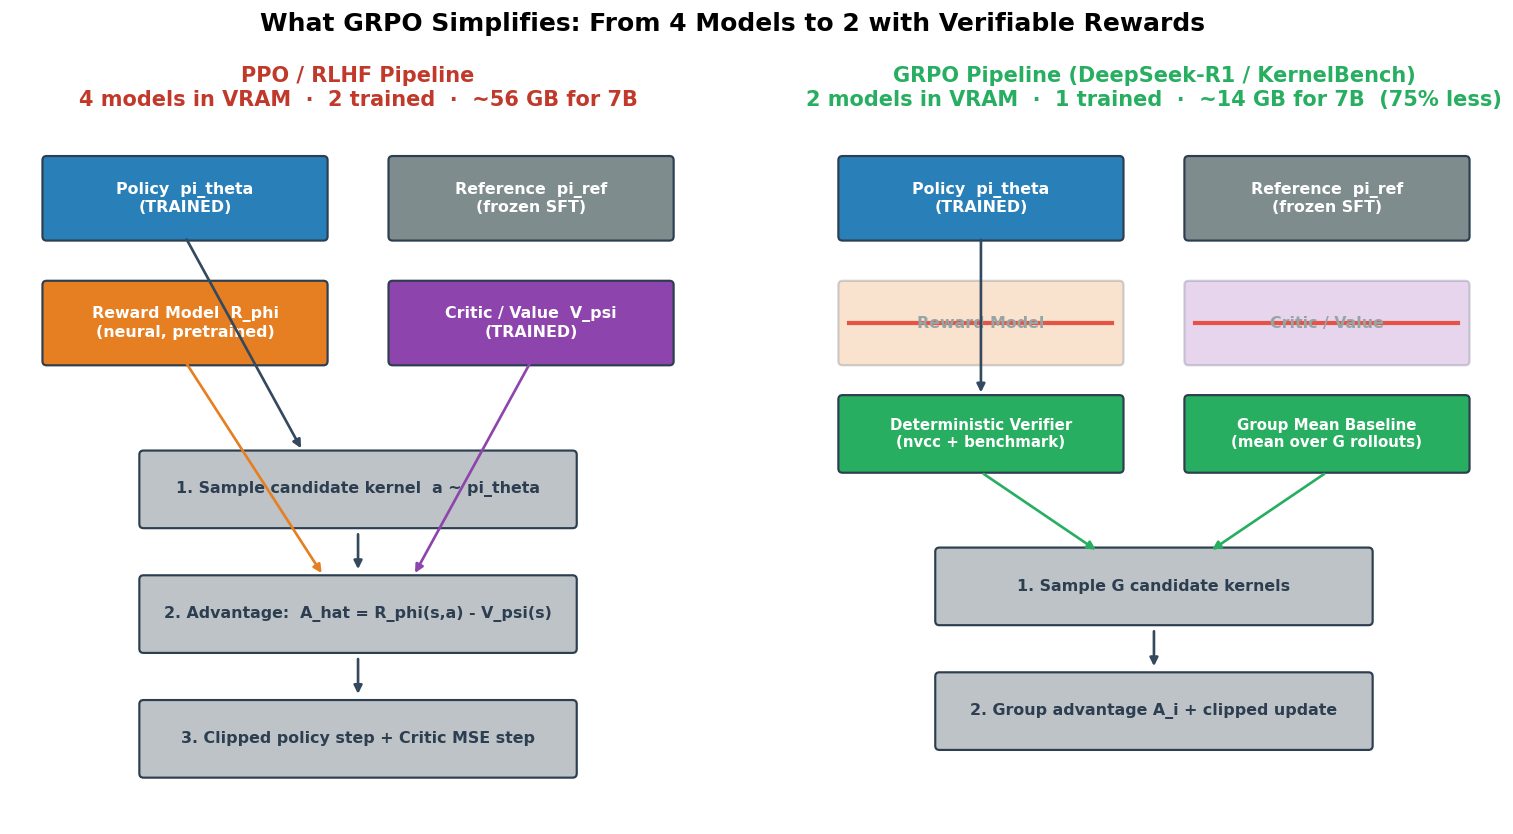

In [1]:
# === Section 1.4: Pipeline Comparison Diagram — PPO/RLHF vs GRPO ===
# (Schematic illustration. Run to regenerate figures/00_pipeline_comparison.png)

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

def draw_box(ax, cx, cy, w, h, text, color, alpha=1.0, strikethrough=False, fontsize=9.5, text_color=None):
    rect = mpatches.FancyBboxPatch((cx - w/2, cy - h/2), w, h, boxstyle="round,pad=0.006",
                                    facecolor=color, edgecolor='#2c3e50', linewidth=1.3, alpha=alpha)
    ax.add_patch(rect)
    tc = text_color if text_color else ('white' if alpha > 0.5 else '#95a5a6')
    ax.text(cx, cy, text, ha='center', va='center', fontsize=fontsize, fontweight='bold', color=tc)
    if strikethrough:
        ax.plot([cx - w/2 + 0.01, cx + w/2 - 0.01], [cy, cy], color='#e74c3c', linewidth=2.5, alpha=0.95)

def draw_arrow(ax, start, end, color='#34495e'):
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='-|>', color=color, lw=1.6, shrinkA=2, shrinkB=2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.5))
BW, BH = 0.40, 0.11

# ================= LEFT: PPO / RLHF (4 models) =================
ax1.set_xlim(0, 1); ax1.set_ylim(0, 1); ax1.axis('off')
ax1.set_title('PPO / RLHF Pipeline\n4 models in VRAM  ·  2 trained  ·  ~56 GB for 7B',
              fontsize=12.5, fontweight='bold', color='#c0392b', pad=14)

# Row of 4 models (top)
draw_box(ax1, 0.25, 0.90, BW, BH, 'Policy  pi_theta\n(TRAINED)', '#2980b9')
draw_box(ax1, 0.75, 0.90, BW, BH, 'Reference  pi_ref\n(frozen SFT)', '#7f8c8d')
draw_box(ax1, 0.25, 0.72, BW, BH, 'Reward Model  R_phi\n(neural, pretrained)', '#e67e22')
draw_box(ax1, 0.75, 0.72, BW, BH, 'Critic / Value  V_psi\n(TRAINED)', '#8e44ad')

# Pipeline flow (bottom)
draw_box(ax1, 0.50, 0.48, 0.62, 0.10, '1. Sample candidate kernel  a ~ pi_theta', '#bdc3c7', text_color='#2c3e50')
draw_box(ax1, 0.50, 0.30, 0.62, 0.10, '2. Advantage:  A_hat = R_phi(s,a) - V_psi(s)', '#bdc3c7', text_color='#2c3e50')
draw_box(ax1, 0.50, 0.12, 0.62, 0.10, '3. Clipped policy step + Critic MSE step', '#bdc3c7', text_color='#2c3e50')

draw_arrow(ax1, (0.25, 0.845), (0.42, 0.535))   # policy -> sample
draw_arrow(ax1, (0.25, 0.665), (0.45, 0.355), '#e67e22')  # reward -> advantage
draw_arrow(ax1, (0.75, 0.665), (0.58, 0.355), '#8e44ad')  # critic -> advantage
draw_arrow(ax1, (0.50, 0.42), (0.50, 0.36))
draw_arrow(ax1, (0.50, 0.24), (0.50, 0.18))

# ================= RIGHT: GRPO (2 models) =================
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1); ax2.axis('off')
ax2.set_title('GRPO Pipeline (DeepSeek-R1 / KernelBench)\n2 models in VRAM  ·  1 trained  ·  ~14 GB for 7B  (75% less)',
              fontsize=12.5, fontweight='bold', color='#27ae60', pad=14)

# Kept models (top)
draw_box(ax2, 0.25, 0.90, BW, BH, 'Policy  pi_theta\n(TRAINED)', '#2980b9')
draw_box(ax2, 0.75, 0.90, BW, BH, 'Reference  pi_ref\n(frozen SFT)', '#7f8c8d')
# Removed models (struck through)
draw_box(ax2, 0.25, 0.72, BW, BH, 'Reward Model', '#e67e22', alpha=0.22, strikethrough=True)
draw_box(ax2, 0.75, 0.72, BW, BH, 'Critic / Value', '#8e44ad', alpha=0.22, strikethrough=True)
# GRPO replacements
draw_box(ax2, 0.25, 0.56, BW, 0.10, 'Deterministic Verifier\n(nvcc + benchmark)', '#27ae60', fontsize=9)
draw_box(ax2, 0.75, 0.56, BW, 0.10, 'Group Mean Baseline\n(mean over G rollouts)', '#27ae60', fontsize=9)

# Pipeline flow (bottom)
draw_box(ax2, 0.50, 0.34, 0.62, 0.10, '1. Sample G candidate kernels', '#bdc3c7', text_color='#2c3e50')
draw_box(ax2, 0.50, 0.16, 0.62, 0.10, '2. Group advantage A_i + clipped update', '#bdc3c7', text_color='#2c3e50')

draw_arrow(ax2, (0.25, 0.845), (0.25, 0.615))       # policy -> verifier
draw_arrow(ax2, (0.25, 0.505), (0.42, 0.39), '#27ae60')  # verifier -> sample
draw_arrow(ax2, (0.75, 0.505), (0.58, 0.39), '#27ae60')  # group mean -> sample
draw_arrow(ax2, (0.50, 0.28), (0.50, 0.22))

fig.suptitle('What GRPO Simplifies: From 4 Models to 2 with Verifiable Rewards',
             fontsize=15, fontweight='bold', y=1.01)
plt.subplots_adjust(wspace=0.15)
plt.savefig('../figures/00_pipeline_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### 1.5 The Variance Problem and Why Baselines Matter

Now that we see what GRPO replaces and how it fits into the RL landscape, let's understand *why the baseline matters so much*.

The policy gradient we defined in Section 1.2 has a critical practical problem:

$$
\nabla_\theta J = \mathbb{E}\left[ R \cdot \nabla_\theta \log \pi_\theta(a) \right]
$$

If all rewards are positive (e.g., partial credit scores between 0 and 1), then *every* action gets pushed up -- just by different amounts. The gradient is technically correct in expectation, but the **variance is enormous**. Training is noisy, slow, and unstable.

#### The baseline trick (Williams, 1992)

Subtract a **baseline** $b$ from the reward:

$$
\nabla_\theta J = \mathbb{E}\left[ (R - b) \cdot \nabla_\theta \log \pi_\theta(a) \right]
$$

This doesn't change the expected gradient (since the expectation of the score function is zero), but it **centers** the learning signal: actions with above-baseline reward get reinforced, actions with below-baseline reward get suppressed.

#### Three approaches to the baseline

| Approach | Baseline (b) | Pros | Cons |
|---|---|---|---|
| **No baseline** (REINFORCE) | b = 0 | Simple | Enormous variance |
| **PPO** | Learned critic V_psi(s) | Adaptive, low variance | Requires training a separate model |
| **GRPO** | Group mean  R_bar = (1/G) * sum(R_i) | Free, no extra model | Depends on group diversity |

GRPO's group-mean baseline is the simplest possible choice: generate $G$ responses, compute their average reward, and subtract it. The figure below shows why even this simple baseline makes a dramatic difference.

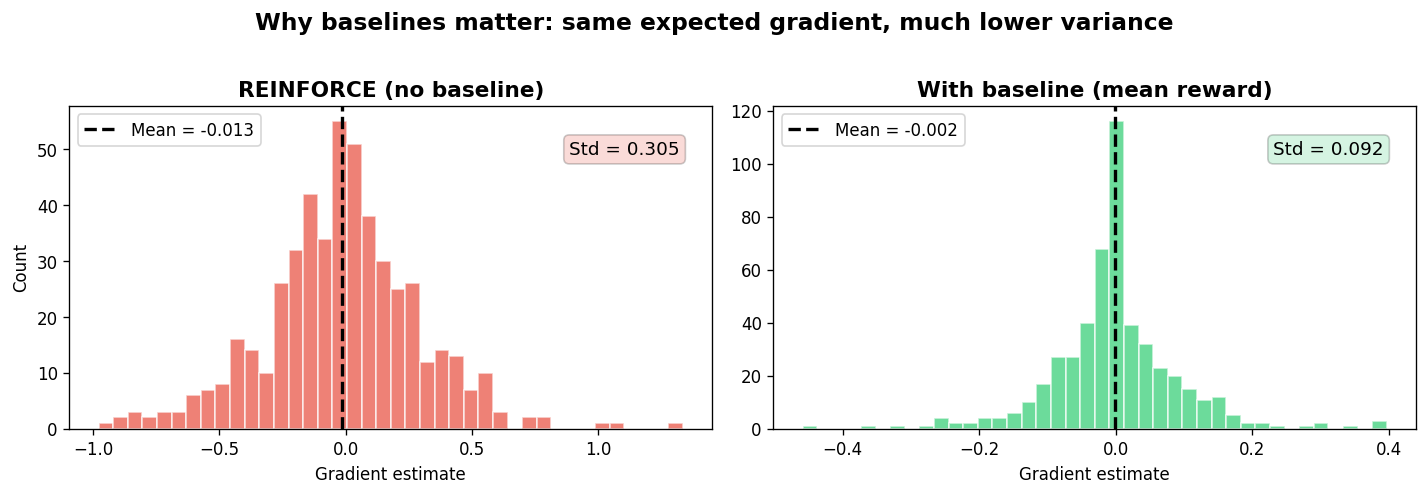

Variance reduction: 0.0928 -> 0.0085 (90.8% reduction)


In [2]:
# === Section 1: Visualizing the variance reduction from baselines ===

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['figure.figsize'] = (10, 4)
np.random.seed(42)

# Simulate: 5 actions, each with a reward drawn from some distribution
n_samples = 500
rewards = np.random.beta(3, 2, size=n_samples)  # rewards in [0, 1], mean ~0.6
log_probs = np.random.randn(n_samples) * 0.5     # simulated grad log pi

# REINFORCE gradient (no baseline)
reinforce_grads = rewards * log_probs

# With optimal baseline (mean reward)
baseline = rewards.mean()
baselined_grads = (rewards - baseline) * log_probs

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(reinforce_grads, bins=40, alpha=0.7, color='#e74c3c', edgecolor='white')
axes[0].axvline(reinforce_grads.mean(), color='black', linestyle='--', linewidth=2,
                label=f'Mean = {reinforce_grads.mean():.3f}')
axes[0].set_title('REINFORCE (no baseline)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Gradient estimate')
axes[0].set_ylabel('Count')
axes[0].legend()
axes[0].annotate(f'Std = {reinforce_grads.std():.3f}', xy=(0.95, 0.85),
                 xycoords='axes fraction', ha='right', fontsize=11,
                 bbox=dict(boxstyle='round', facecolor='#e74c3c', alpha=0.2))

axes[1].hist(baselined_grads, bins=40, alpha=0.7, color='#2ecc71', edgecolor='white')
axes[1].axvline(baselined_grads.mean(), color='black', linestyle='--', linewidth=2,
                label=f'Mean = {baselined_grads.mean():.3f}')
axes[1].set_title('With baseline (mean reward)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Gradient estimate')
axes[1].legend()
axes[1].annotate(f'Std = {baselined_grads.std():.3f}', xy=(0.95, 0.85),
                 xycoords='axes fraction', ha='right', fontsize=11,
                 bbox=dict(boxstyle='round', facecolor='#2ecc71', alpha=0.2))

fig.suptitle('Why baselines matter: same expected gradient, much lower variance',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/01_baseline_variance.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Variance reduction: {reinforce_grads.var():.4f} -> {baselined_grads.var():.4f} "
      f"({(1 - baselined_grads.var()/reinforce_grads.var())*100:.1f}% reduction)")

## Section 2: Setup — KernelBench Task Specifications & CPU Micro-Environments

We ground the tutorial in a real verifiable-reward domain -- **GPU kernel generation** -- using the public **KernelBench** benchmark (Ouyang et al., ICML 2025). The file `data/kernelbench/tasks.json` contains:

1. **Real task specifications** referencing actual KernelBench Level-1 problems by ID and name -- `1_Square_matrix_multiplication_`, `23_Softmax`, `40_LayerNorm` -- each with its PyTorch reference module and input shapes.
2. **Candidate kernels** spanning the characteristic behaviors reported for this benchmark: naive global-memory loops, uncoalesced access, register-spilling tiles, the optimal shared-memory + coalesced tile, shared-memory overflows (compile errors), and data races (accuracy mismatches).
3. **Illustrative benchmark outcomes** -- compile status, numerical parity, latency (µs), and speedup -- chosen to reflect the qualitative patterns documented in KernelBench and Kevin (Baronio et al., 2025).

> **Honest scope.** The latency/speedup values are *illustrative*, not measured by live `nvcc` execution in this CPU-only notebook. They are realistic and internally consistent, and each task carries a `metrics_note` recording this. See `data/kernelbench/README.md` for provenance and instructions to reproduce the numbers on real GPU hardware with the official harness.

To keep every equation, gradient step, and loss calculation transparent and runnable on any laptop, we map these task specifications to two **minimal micro-environments**:

| Micro-Environment | KernelBench Framing | Formulation | Failure Modes Demonstrated |
|---|---|---|---|
| **Level A: Micro-Bandit** | **Kernel configuration selection** for the Square-Matmul problem: pick the tile/block geometry (16x16, 32x32, 64x64, shared-memory layouts) | 8-action categorical policy with a deterministic reward from the task's candidate outcomes | Zero-gradient groups, group-size scaling (G), advantage normalization |
| **Level B: Micro-Sequence** | **Multi-stage kernel construction:** emit the 4 core stages of a tiled kernel (alloc_shared -> load_coalesced -> tile_compute -> sync_store) | 4-step autoregressive categorical policy with a sequence verifier | Entropy collapse, clipping asymmetry, length bias, credit assignment |

Let's load the KernelBench task specifications from disk and inspect them.

In [3]:
# === Section 2: Shared utilities and KernelBench task specifications ===

import warnings
warnings.filterwarnings('ignore')
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# --- Load KernelBench task specifications (real problem specs; illustrative metrics) ---
kb_data_path = os.path.join('..', 'data', 'kernelbench', 'tasks.json')
if not os.path.exists(kb_data_path):
    kb_data_path = os.path.join('data', 'kernelbench', 'tasks.json')

with open(kb_data_path, 'r', encoding='utf-8') as f:
    kb_tasks = json.load(f)

print(f"Loaded {len(kb_tasks)} KernelBench task specifications from {kb_data_path}.")
print(f"  (real problem specs; illustrative benchmark metrics -- see data/kernelbench/README.md)")

# Select the Level 1 Square-Matmul problem (KernelBench problem_id=1)
matmul_task = kb_tasks[0]
print(f"\n--- Workload: {matmul_task['name']} ---")
print(f"Description: {matmul_task['description']}")
print(f"KernelBench ref: problem_id={matmul_task['kernelbench_problem_id']} ({matmul_task['kernelbench_problem_name']})")
print(f"PyTorch Baseline Latency (illustrative): {matmul_task['pytorch_baseline_latency_us']:.1f} us\n")

# --- Configuration ---
class Config:
    """Global configuration for all experiments."""
    seed = 42
    # Bandit (Level A) — Micro-Kernel Selection: 8 candidate kernel configurations
    bandit_n_actions = len(matmul_task['candidates'])
    bandit_correct_action = 3     # index of optimal configuration (Tile 32x32 + SharedMem)
    bandit_group_size = 8         # G: candidate rollouts per prompt
    bandit_lr = 0.5               # learning rate
    bandit_n_steps = 200          # training steps
    # Sequence (Level B) — Multi-step CUDA Optimization Pipeline
    seq_vocab_size = 6            # vocabulary of CUDA kernel optimization stages
    seq_length = 4                # 4-stage pipeline
    seq_group_size = 16           # G for sequence tasks
    seq_lr = 0.1
    seq_n_steps = 300
    # GRPO hyperparameters
    clip_eps = 0.2                # PPO/GRPO clipping epsilon
    kl_coeff = 0.01              # KL penalty coefficient

cfg = Config()
np.random.seed(cfg.seed)

# Extract real candidates
BANDIT_LABELS = [c['name'] + f"  [{c['status']}]" for c in matmul_task['candidates']]
BANDIT_CANDIDATES = matmul_task['candidates']
BANDIT_PROBLEM = f"KernelBench ({matmul_task['task_id']}): {matmul_task['description']}"

# Level B: 6-stage vocabulary for CUDA kernel generation
# Target sequence [2, 0, 4, 1] = ["alloc_shared", "load_coalesced", "tile_compute", "sync_store"]
SEQ_VOCAB_LABELS = [
    "load_coalesced", # 0
    "sync_store",     # 1
    "alloc_shared",   # 2
    "busy_wait",      # 3
    "tile_compute",   # 4
    "assert_check",   # 5
]
SEQ_TARGET = [2, 0, 4, 1]  # "alloc_shared" -> "load_coalesced" -> "tile_compute" -> "sync_store"
SEQ_TARGET_READABLE = " -> ".join(SEQ_VOCAB_LABELS[t] for t in SEQ_TARGET)

def action_label(action_idx):
    """Return the KernelBench configuration label for a bandit action."""
    return BANDIT_LABELS[action_idx]

def seq_label(seq):
    """Return readable labels for a sequence of token indices."""
    return " -> ".join(SEQ_VOCAB_LABELS[t] for t in seq)

# --- Softmax utility ---
def softmax(logits):
    """Numerically stable softmax."""
    x = logits - logits.max()
    e = np.exp(x)
    return e / e.sum()

# --- Entropy ---
def entropy(probs):
    """Shannon entropy of a probability distribution."""
    p = probs[probs > 1e-10]
    return -np.sum(p * np.log(p))

# --- Level A: KernelBench-framed Bandit Environment ---
class BanditVerifier:
    """Deterministic verifier reading each candidate's recorded outcome
    (models the KernelBench nvcc-compile + correctness + speedup check)."""
    def __init__(self, candidates, correct_action=3, noise_prob=0.0):
        self.candidates = candidates
        self.correct = correct_action
        self.noise_prob = noise_prob

    def __call__(self, action):
        cand = self.candidates[action]
        # Verifiable reward: 1.0 iff the candidate compiles, matches PyTorch, and beats the 1.2x speedup threshold
        reward = float(cand['reward'])
        if np.random.random() < self.noise_prob:
            reward = 1.0 - reward
        return reward

    def success_rate(self, probs):
        """Expected success rate given current policy."""
        return probs[self.correct]

# --- Level B: Sequence Environment ---
class SequenceVerifier:
    """Verifier for multi-step CUDA optimization pipelines. Returns 1.0 if pipeline is correct."""
    def __init__(self, target_sequence):
        self.target = np.array(target_sequence)

    def __call__(self, sequence):
        """Returns 1.0 if sequence matches target pipeline exactly, else 0.0."""
        return 1.0 if np.array_equal(sequence, self.target) else 0.0

class SequencePolicy:
    """Autoregressive categorical policy across pipeline positions."""
    def __init__(self, seq_length, vocab_size):
        self.seq_length = seq_length
        self.vocab_size = vocab_size
        self.logits = np.zeros((seq_length, vocab_size))

    def sample(self):
        """Sample a pipeline and return (sequence, log_probs_per_token)."""
        seq = []
        log_probs = []
        for t in range(self.seq_length):
            probs = softmax(self.logits[t])
            action = np.random.choice(self.vocab_size, p=probs)
            seq.append(action)
            log_probs.append(np.log(probs[action] + 1e-10))
        return np.array(seq), np.array(log_probs)

    def log_prob(self, sequence):
        """Compute log probs for a given sequence under current policy."""
        lps = []
        for t in range(self.seq_length):
            probs = softmax(self.logits[t])
            lps.append(np.log(probs[sequence[t]] + 1e-10))
        return np.array(lps)

    def get_entropy(self):
        """Average entropy across pipeline stages."""
        return np.mean([entropy(softmax(self.logits[t]))
                        for t in range(self.seq_length)])

    def copy(self):
        """Return a frozen copy (for reference policy / importance sampling)."""
        p = SequencePolicy(self.seq_length, self.vocab_size)
        p.logits = self.logits.copy()
        return p

print("Setup complete.")
print(f"\nLevel A — Micro-Bandit on KernelBench Square-Matmul ({cfg.bandit_n_actions} candidate kernels):")
for i, c in enumerate(BANDIT_CANDIDATES):
    marker = " <-- [TARGET]" if i == cfg.bandit_correct_action else ""
    print(f"  [{i}] {c['name']:<48} | Latency: {c['latency_us']:>5.1f} µs | Speedup: {c['speedup']:>4.2f}x | Reward: {c['reward']}{marker}")

print(f"\nLevel B — Micro-Sequence (CUDA Optimization Pipeline):")
print(f"  Stages: {SEQ_VOCAB_LABELS}")
print(f"  Target Pipeline ({cfg.seq_length} stages): {SEQ_TARGET_READABLE}")
print(f"  Verifier: Deterministic execution & validation test harness")

Loaded 3 KernelBench task specifications from ../data/kernelbench/tasks.json.
  (real problem specs; illustrative benchmark metrics -- see data/kernelbench/README.md)

--- Workload: KernelBench L1-P1: Square Matrix Multiplication (C = A @ B) ---
Description: Reference PyTorch op: C = A @ B for square matrices (N=2048). The LLM must emit a custom CUDA kernel; here we model the choice of tiling/block configuration.
KernelBench ref: problem_id=1 (1_Square_matrix_multiplication_)
PyTorch Baseline Latency (illustrative): 142.5 us

Setup complete.

Level A — Micro-Bandit on KernelBench Square-Matmul (8 candidate kernels):
  [0] Tile 16x16 (Naive global loads)                  | Latency: 178.1 µs | Speedup: 0.80x | Reward: 0.0
  [1] Tile 16x32 (Uncoalesced strided memory)          | Latency: 156.6 µs | Speedup: 0.91x | Reward: 0.0
  [2] Tile 64x64 (Register pressure spill)             | Latency: 192.5 µs | Speedup: 0.74x | Reward: 0.0
  [3] Tile 32x32 + SharedMem + Coalesced               | L

## Section 3: GRPO by Hand — The Bandit-Kernel Selection Case

Let's trace GRPO's core mathematical update step by step. For a prompt $s$, GRPO executes:

1. **Sample Group:** Generate $G$ candidate rollouts $\{a_1, \dots, a_G\} \sim \pi_\theta(\cdot \mid s)$.
2. **Score with Verifier:** Evaluate each candidate with the execution verifier to obtain rewards $\{R_1, \dots, R_G\}$.
3. **Compute Group-Relative Advantage:**
   $$A_i = \frac{R_i - \text{mean}(R_1, \dots, R_G)}{\text{std}(R_1, \dots, R_G) + \epsilon}$$
4. **Policy Update:** Increase the generation probability of above-average candidates ($A_i > 0$) and decrease below-average ones ($A_i < 0$).

Notice again: **the group itself is the baseline**. There is no critic model, no value network, and no learned reward model.

Let's compute this by hand in Python for our Kernel Selection task.

In [4]:
# === Section 3: GRPO by hand on real KernelBench candidates ===

verifier_bandit = BanditVerifier(BANDIT_CANDIDATES, correct_action=cfg.bandit_correct_action)

# Step 1: Initial policy (uniform over 8 candidate kernels)
logits = np.zeros(cfg.bandit_n_actions)
probs = softmax(logits)
print("Initial policy (uniform over 8 candidate CUDA kernels):")
print(f"  P(optimal = '{BANDIT_CANDIDATES[cfg.bandit_correct_action]['name']}') = {probs[cfg.bandit_correct_action]:.3f}\n")

# Step 2: A representative group of G=8 rollouts for this prompt.
# We show a group that CONTAINS the optimal kernel (index 3) so the advantage
# signal is visible. (A group with no correct kernel would give std=0 and ZERO
# gradient -- we explore that failure mode explicitly in Section 5.1.)
G = cfg.bandit_group_size
group_actions = np.array([2, 3, 5, 0, 4, 1, 3, 7])  # includes the optimal kernel (idx 3) twice

# Step 3: Score each rollout with the real KernelBench execution verifier
group_rewards = np.array([verifier_bandit(a) for a in group_actions])

# Step 4: Compute group-relative advantages
r_mean = group_rewards.mean()
r_std = group_rewards.std()
advantages = (group_rewards - r_mean) / (r_std + 1e-8)

print(f"Group of {G} sampled kernels (the model's {G} attempts at this prompt):")
for i, (act, rew) in enumerate(zip(group_actions, group_rewards)):
    tag = "  <-- OPTIMAL (2.34x speedup)" if act == cfg.bandit_correct_action else ""
    print(f"  [{i}] {BANDIT_CANDIDATES[act]['name']:<42} reward={int(rew)}{tag}")

print(f"\n  Mean(R): {r_mean:.3f},  Std(R): {r_std:.3f}\n")
print("Group-relative advantages  A_i = (R_i - mean) / (std + eps):")
for i, (act, adv) in enumerate(zip(group_actions, advantages)):
    marker = "  <-- reinforced" if adv > 0 else "  <-- suppressed"
    print(f"  [{i}] {BANDIT_CANDIDATES[act]['name']:<42} A={adv:+.3f}{marker}")

print(f"\nSum of advantages: {advantages.sum():.6f} (centered at ~0 by the group-mean baseline)")

Initial policy (uniform over 8 candidate CUDA kernels):
  P(optimal = 'Tile 32x32 + SharedMem + Coalesced') = 0.125

Group of 8 sampled kernels (the model's 8 attempts at this prompt):
  [0] Tile 64x64 (Register pressure spill)       reward=0
  [1] Tile 32x32 + SharedMem + Coalesced         reward=1  <-- OPTIMAL (2.34x speedup)
  [2] Tile 32x16 (Shared memory bank conflicts)  reward=0
  [3] Tile 16x16 (Naive global loads)            reward=0
  [4] Tile 8x8 (Low occupancy under-utilization) reward=0
  [5] Tile 16x32 (Uncoalesced strided memory)    reward=0
  [6] Tile 32x32 + SharedMem + Coalesced         reward=1  <-- OPTIMAL (2.34x speedup)
  [7] Tile 16x16 + Non-atomic accum (race)       reward=0

  Mean(R): 0.250,  Std(R): 0.433

Group-relative advantages  A_i = (R_i - mean) / (std + eps):
  [0] Tile 64x64 (Register pressure spill)       A=-0.577  <-- suppressed
  [1] Tile 32x32 + SharedMem + Coalesced         A=+1.732  <-- reinforced
  [2] Tile 32x16 (Shared memory bank conflicts)  

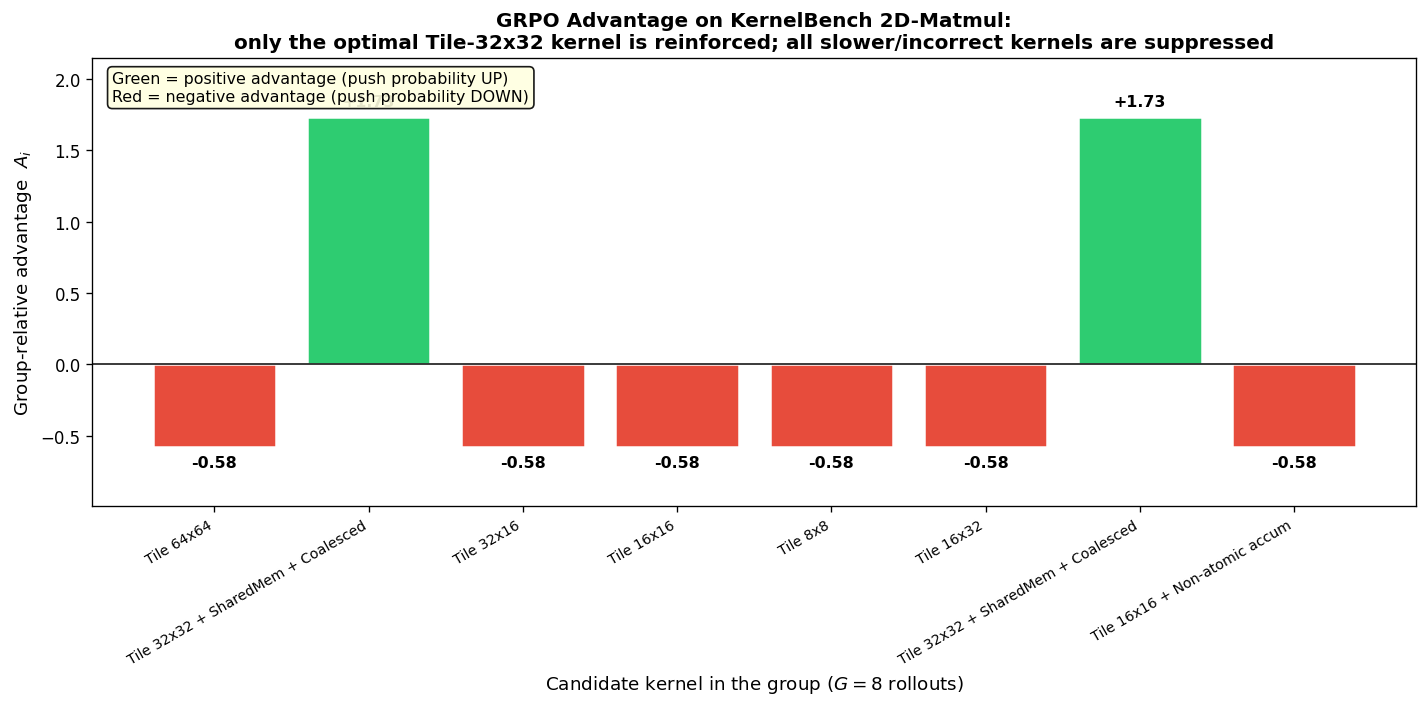

In [5]:
# === Section 3 (cont): Visualize the group-relative advantages ===

fig, ax = plt.subplots(figsize=(12, 6))

colors = ['#2ecc71' if a > 0 else '#e74c3c' for a in advantages]
bars = ax.bar(range(G), advantages, color=colors, edgecolor='white', linewidth=1.5)

# Value label on top of each bar
for i, adv in enumerate(advantages):
    va = 'bottom' if adv >= 0 else 'top'
    off = 0.06 if adv >= 0 else -0.06
    ax.text(i, adv + off, f'{adv:+.2f}', ha='center', va=va, fontsize=9.5, fontweight='bold')

# Short, readable x-tick labels (just the tile configuration name)
short_labels = [BANDIT_CANDIDATES[a]['name'].split('(')[0].strip() for a in group_actions]
ax.set_xticks(range(G))
ax.set_xticklabels(short_labels, rotation=30, ha='right', fontsize=8.5)

ax.axhline(0, color='black', linewidth=0.9)
ax.set_xlabel('Candidate kernel in the group ($G=8$ rollouts)', fontsize=11)
ax.set_ylabel('Group-relative advantage  $A_i$', fontsize=11)
ax.set_title('GRPO Advantage on KernelBench 2D-Matmul:\nonly the optimal Tile-32x32 kernel is reinforced; all slower/incorrect kernels are suppressed',
             fontsize=12, fontweight='bold')
ax.margins(y=0.18)

ax.annotate('Green = positive advantage (push probability UP)\nRed = negative advantage (push probability DOWN)',
            xy=(0.015, 0.97), xycoords='axes fraction', fontsize=9.5, va='top',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9))

plt.tight_layout()
plt.savefig('../figures/02_advantage_bars.png', dpi=150, bbox_inches='tight')
plt.show()

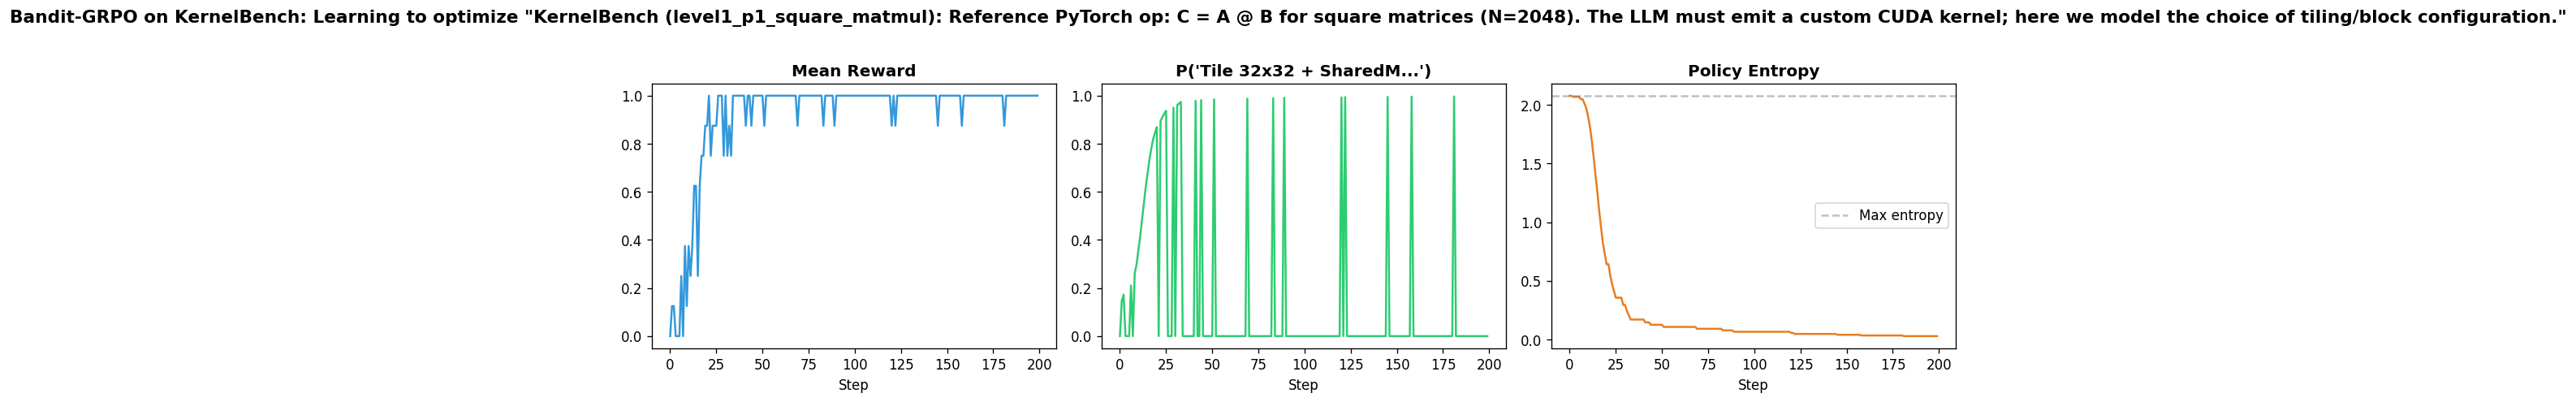


Final policy after 200 steps:
  [0] P=  0.001  'Tile 16x16 (Naive global loads)  [SLOWER (0.80x)]'
  [1] P=  0.000  'Tile 16x32 (Uncoalesced strided memory)  [SLOWER (0.91x)]'
  [2] P=  0.001  'Tile 64x64 (Register pressure spill)  [SLOWER (0.74x)]'
  [3] P=  0.997  'Tile 32x32 + SharedMem + Coalesced  [FAST_P OPTIMAL (2.34x speedup)]' <-- OPTIMAL (2.34x speedup)
  [4] P=  0.000  'Tile 8x8 (Low occupancy under-utilization)  [SLOWER (0.53x)]'
  [5] P=  0.000  'Tile 32x16 (Shared memory bank conflicts)  [SLOWER (0.94x)]'
  [6] P=  0.001  'Tile 128x128 (Shared mem capacity overflow)  [COMPILE_ERROR]'
  [7] P=  0.000  'Tile 16x16 + Non-atomic accum (race)  [ACCURACY_MISMATCH]'


In [6]:
# === Section 3 (cont): Implement Bandit-GRPO in ~30 lines ===

def bandit_grpo_step(logits, verifier, group_size, lr):
    """One step of Bandit-GRPO. Returns updated logits and diagnostics."""
    probs = softmax(logits)

    # 1. Sample group of G responses
    actions = np.random.choice(len(logits), size=group_size, p=probs)
    rewards = np.array([verifier(a) for a in actions])

    # 2. Compute group-relative advantages
    r_std = rewards.std()
    if r_std < 1e-8:  # all same reward -> no signal (zero-gradient group!)
        return logits, {
            'reward_mean': rewards.mean(), 'entropy': entropy(probs),
            'grad_norm': 0.0, 'zero_grad': True
        }
    advantages = (rewards - rewards.mean()) / r_std

    # 3. Policy gradient: d/d(logits[a]) = advantage * (1[sampled=a] - probs[a])
    grad = np.zeros_like(logits)
    for a, adv in zip(actions, advantages):
        one_hot = np.zeros_like(logits)
        one_hot[a] = 1.0
        grad += adv * (one_hot - probs)  # REINFORCE gradient with group baseline
    grad /= group_size

    # 4. Update
    logits = logits + lr * grad

    return logits, {
        'reward_mean': rewards.mean(), 'entropy': entropy(softmax(logits)),
        'grad_norm': np.linalg.norm(grad), 'zero_grad': False,
        'p_correct': softmax(logits)[verifier.correct]
    }

# --- Train ---
np.random.seed(cfg.seed)
logits = np.zeros(cfg.bandit_n_actions)
verifier = BanditVerifier(BANDIT_CANDIDATES, correct_action=cfg.bandit_correct_action)
history = []

for step in range(cfg.bandit_n_steps):
    logits, info = bandit_grpo_step(logits, verifier, cfg.bandit_group_size, cfg.bandit_lr)
    history.append(info)

# --- Plot training ---
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot([h['reward_mean'] for h in history], color='#3498db', linewidth=1.5)
axes[0].set_title('Mean Reward', fontweight='bold')
axes[0].set_xlabel('Step')
axes[0].set_ylim(-0.05, 1.05)

axes[1].plot([h.get('p_correct', 0) for h in history], color='#2ecc71', linewidth=1.5)
axes[1].set_title(f"P('{BANDIT_CANDIDATES[cfg.bandit_correct_action]['name'][:20]}...')", fontweight='bold')
axes[1].set_xlabel('Step')
axes[1].set_ylim(-0.05, 1.05)

axes[2].plot([h['entropy'] for h in history], color='#e67e22', linewidth=1.5)
axes[2].axhline(np.log(cfg.bandit_n_actions), color='gray', linestyle='--',
                alpha=0.5, label='Max entropy')
axes[2].set_title('Policy Entropy', fontweight='bold')
axes[2].set_xlabel('Step')
axes[2].legend()

fig.suptitle(f'Bandit-GRPO on KernelBench: Learning to optimize "{BANDIT_PROBLEM}"',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/03_bandit_training.png', dpi=150, bbox_inches='tight')
plt.show()

final_probs = softmax(logits)
print(f"\nFinal policy after {cfg.bandit_n_steps} steps:")
for i, (p, label) in enumerate(zip(final_probs, BANDIT_LABELS)):
    marker = " <-- OPTIMAL (2.34x speedup)" if i == cfg.bandit_correct_action else ""
    print(f"  [{i}] P=  {p:.3f}  '{label}'{marker}")

### Key Observation: Learning from Group Contrast

With ~30 lines of code and zero learned critic weights, GRPO rapidly learns to identify the optimal kernel configuration (`Tile 32x32 + SharedMem`). 

The learning signal is driven entirely by **group contrast**: the optimal configuration is reinforced whenever it appears alongside suboptimal configurations in the same group.

*Next, let's extend this to full autoregressive token sequences with clipping and KL regularization.*

## Section 4: The Full GRPO Objective — Sequence-Kernel Optimization

While the bandit case is intuitive, production reasoning and code generation models operate on **multi-token autoregressive sequences**. Full GRPO incorporates three essential mechanisms from PPO:

1. **Importance Sampling Ratio:** When performing multiple gradient steps per rollout batch, the policy shifts from $\pi_{\text{old}}$ (which generated the rollout) to $\pi_\theta$ (being updated):

$$
r_{i,t}(\theta) = \frac{\pi_\theta(a_{i,t} \mid a_{i,<t}, s)}{\pi_{\text{old}}(a_{i,t} \mid a_{i,<t}, s)}
$$

2. **Clipped Surrogate Objective:** To prevent catastrophic policy shifts, the ratio is clipped to $[1-\epsilon, 1+\epsilon]$:

$$
\mathcal{L}_{\text{clip}}(\theta) = \min\left( r_{i,t}(\theta) A_i, \; \text{clip}(r_{i,t}(\theta), 1-\epsilon, 1+\epsilon) A_i \right)
$$

3. **KL Regularization Penalty:** A per-token penalty prevents the policy from drifting too far from the reference model $\pi_{\text{ref}}$:

$$
\mathbb{D}_{\text{KL}}(\pi_\theta \parallel \pi_{\text{ref}}) = \frac{\pi_{\text{ref}}(a_{i,t})}{\pi_\theta(a_{i,t})} - \log \frac{\pi_{\text{ref}}(a_{i,t})}{\pi_\theta(a_{i,t})} - 1
$$

Combining these yields the full Sequence-GRPO objective:

$$
\mathcal{L}_{\text{GRPO}}(\theta) = -\frac{1}{G}\sum_{i=1}^G \frac{1}{|o_i|} \sum_{t=1}^{|o_i|} \left[ \min\left( r_{i,t}(\theta) A_i, \text{clip}(r_{i,t}(\theta), 1-\epsilon, 1+\epsilon) A_i \right) - \beta \mathbb{D}_{\text{KL}}(\pi_\theta \parallel \pi_{\text{ref}}) \right]
$$

In [7]:
# === Section 4: Sequence-GRPO with clipping and KL ===

def sequence_grpo_step(policy, ref_policy, verifier, group_size,
                       lr, clip_eps, kl_coeff,
                       token_level_loss=False,
                       clip_higher=None):
    """One step of Sequence-GRPO.

    Args:
        policy: current SequencePolicy
        ref_policy: frozen reference policy (for KL)
        verifier: SequenceVerifier
        group_size: G
        lr: learning rate
        clip_eps: clipping epsilon (lower bound). Also used for upper unless clip_higher is set.
        kl_coeff: beta for KL penalty
        token_level_loss: if True, use token-level aggregation instead of sample-level
        clip_higher: if set, use this as the upper clip bound (DAPO's Clip-Higher)
    """
    old_policy = policy.copy()  # snapshot for importance sampling
    upper_clip = clip_higher if clip_higher is not None else clip_eps

    # 1. Sample group
    sequences = []
    old_log_probs_list = []
    rewards = []
    for _ in range(group_size):
        seq, lps = old_policy.sample()
        sequences.append(seq)
        old_log_probs_list.append(lps)
        rewards.append(verifier(seq))
    rewards = np.array(rewards)

    # 2. Group-relative advantages
    r_std = rewards.std()
    if r_std < 1e-8:
        return policy, {
            'reward_mean': rewards.mean(), 'entropy': policy.get_entropy(),
            'zero_grad': True, 'grad_norm': 0.0
        }
    advantages = (rewards - rewards.mean()) / r_std

    # 3. Compute gradient via numerical differentiation on logits
    # (Cleaner for teaching: explicit per-token clipped objective)
    total_grad = np.zeros_like(policy.logits)
    per_token_weights = []  # for diagnostics

    for i in range(group_size):
        seq = sequences[i]
        adv = advantages[i]
        old_lps = old_log_probs_list[i]
        new_lps = policy.log_prob(seq)
        ref_lps = ref_policy.log_prob(seq)

        for t in range(policy.seq_length):
            # Importance sampling ratio
            ratio = np.exp(new_lps[t] - old_lps[t])

            # Clipped objective
            surr1 = ratio * adv
            surr2 = np.clip(ratio, 1 - clip_eps, 1 + upper_clip) * adv
            obj = min(surr1, surr2)

            # KL penalty (approximate)
            kl_term = kl_coeff * (new_lps[t] - ref_lps[t])

            # Gradient w.r.t. logits[t, seq[t]]
            probs_t = softmax(policy.logits[t])
            # d(log pi) / d(logits[t]) = (1[a] - probs[t]) for the sampled token
            for a in range(policy.vocab_size):
                d_log_pi = (1.0 if a == seq[t] else 0.0) - probs_t[a]

                # Only apply gradient if ratio is not clipped
                if (adv >= 0 and ratio <= 1 + upper_clip) or \
                   (adv < 0 and ratio >= 1 - clip_eps):
                    grad_obj = adv * d_log_pi
                else:
                    grad_obj = 0.0

                grad_kl = -kl_coeff * d_log_pi

                if token_level_loss:
                    # Token-level: weight each token equally across all samples
                    total_grad[t, a] += (grad_obj + grad_kl)
                else:
                    # Sample-level: divide by sequence length (each sample weighted equally)
                    total_grad[t, a] += (grad_obj + grad_kl) / policy.seq_length

            per_token_weights.append(abs(adv) / (policy.seq_length if not token_level_loss else 1))

    total_grad /= group_size

    # 4. Update
    policy.logits = policy.logits + lr * total_grad

    return policy, {
        'reward_mean': rewards.mean(),
        'entropy': policy.get_entropy(),
        'zero_grad': False,
        'grad_norm': np.linalg.norm(total_grad),
        'n_correct': rewards.sum(),
        'per_token_weights': per_token_weights
    }

print("Sequence-GRPO implementation ready.")

Sequence-GRPO implementation ready.


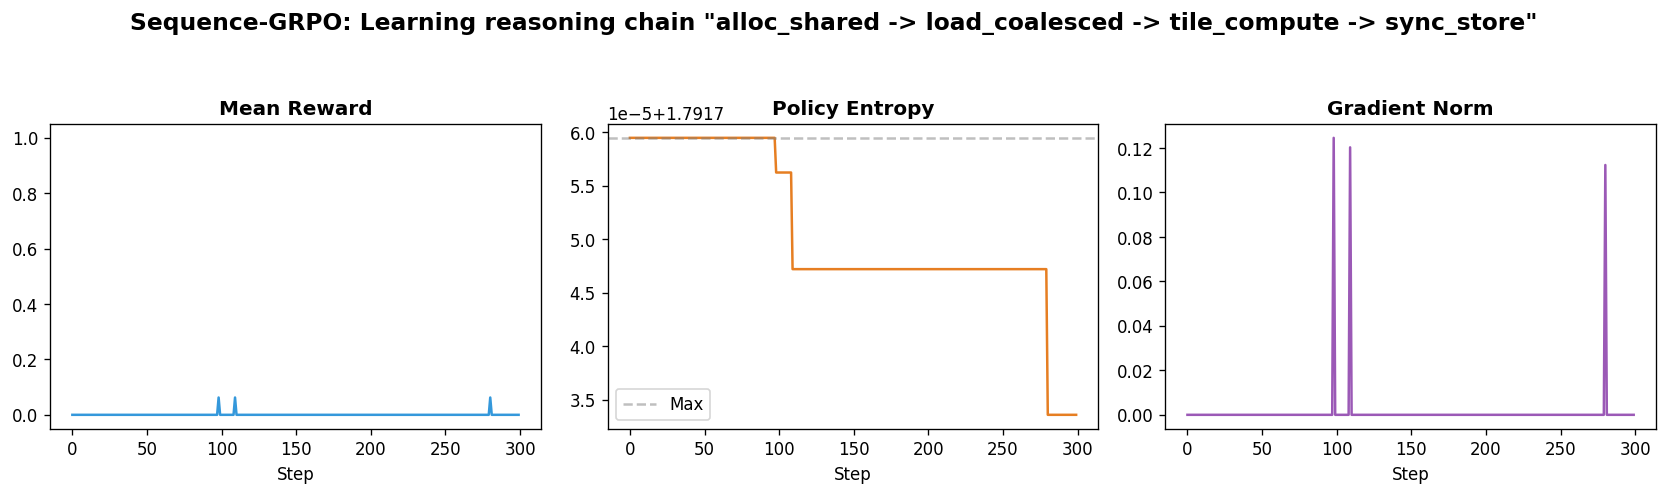


Learned policy (target chain: alloc_shared -> load_coalesced -> tile_compute -> sync_store):
  Step 0: 'alloc_shared' (p=0.169), target = 'alloc_shared'
  Step 1: 'load_coalesced' (p=0.169), target = 'load_coalesced'
  Step 2: 'tile_compute' (p=0.169), target = 'tile_compute'
  Step 3: 'sync_store' (p=0.170), target = 'sync_store'


In [8]:
# === Section 4 (cont): Train Sequence-GRPO on the Countdown reasoning chain ===

np.random.seed(cfg.seed)
target = SEQ_TARGET  # the correct reasoning chain
verifier_seq = SequenceVerifier(target)
policy = SequencePolicy(cfg.seq_length, cfg.seq_vocab_size)
ref_policy = policy.copy()

history_seq = []
for step in range(cfg.seq_n_steps):
    policy, info = sequence_grpo_step(
        policy, ref_policy, verifier_seq,
        group_size=cfg.seq_group_size,
        lr=cfg.seq_lr,
        clip_eps=cfg.clip_eps,
        kl_coeff=cfg.kl_coeff
    )
    history_seq.append(info)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot([h['reward_mean'] for h in history_seq], color='#3498db', linewidth=1.5)
axes[0].set_title('Mean Reward', fontweight='bold')
axes[0].set_xlabel('Step')
axes[0].set_ylim(-0.05, 1.05)

axes[1].plot([h['entropy'] for h in history_seq], color='#e67e22', linewidth=1.5)
axes[1].axhline(np.log(cfg.seq_vocab_size), color='gray', linestyle='--', alpha=0.5, label='Max')
axes[1].set_title('Policy Entropy', fontweight='bold')
axes[1].set_xlabel('Step')
axes[1].legend()

axes[2].plot([h['grad_norm'] for h in history_seq], color='#9b59b6', linewidth=1.5)
axes[2].set_title('Gradient Norm', fontweight='bold')
axes[2].set_xlabel('Step')

fig.suptitle(f'Sequence-GRPO: Learning reasoning chain "{SEQ_TARGET_READABLE}"',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/04_sequence_training.png', dpi=150, bbox_inches='tight')
plt.show()

# Show learned distribution with semantic labels
print(f"\nLearned policy (target chain: {SEQ_TARGET_READABLE}):")
for t in range(cfg.seq_length):
    probs = softmax(policy.logits[t])
    best = np.argmax(probs)
    target_tok = target[t]
    print(f"  Step {t}: '{SEQ_VOCAB_LABELS[best]}' (p={probs[best]:.3f}), target = '{SEQ_VOCAB_LABELS[target_tok]}'")

### What We Have Built So Far

| Component | Status | Mechanism |
|---|---|---|
| **Micro-Bandit (Level A)** | Complete | Evaluates group contrast on discrete kernel configurations |
| **Micro-Sequence (Level B)** | Complete | Generates 4-stage CUDA pipelines with clipping, KL penalty, and autoregressive ratios |
| **Group-Relative Advantage** | Complete | Group mean eliminates the learned critic network |

Now that we understand how GRPO works when everything goes smoothly, let's enter **Part II: The Failure Lab** to see when and why it breaks.

---
# Part II: The Failure Lab

> **Central Principle: GRPO learns only when its rollouts contain informative contrasts -- and fails systematically when the group or verifier provides none.**

Imagine you are deploying GRPO to train a code model on GPU kernel generation. As training proceeds, you encounter three compounding bottlenecks operating at different levels of abstraction:

1. **Macro / Group-Level Bottleneck (Section 5.1):** On very hard or very easy tasks, all rollouts in a group receive identical rewards ($\sigma=0$), causing advantages and gradients to completely vanish.
2. **Micro / Token-Level Bottleneck (Section 5.2):** Even when groups have reward variance, symmetric clipping suppresses rare exploratory tokens, causing policy entropy to collapse into repetitive suboptimal templates.
3. **Structural / Sequence-Level Bottleneck (Section 5.3):** Even with diverse solutions, sample-level loss averaging ($1/|o_i|$) penalizes thorough, multi-step optimization in favor of short, naive stubs.
4. **Systemic / Verifier Bottlenecks (Bonus):** Flawed verifiers enable reward hacking, and outcome rewards create credit assignment ambiguities.

Each failure mode maps directly to an algorithmic innovation in **DAPO** (NeurIPS 2025). Let's explore each one interactively.

## Section 5.1: Failure Mode 1 — Zero-Gradient Groups (Macro Bottleneck)

> **In plain terms:** GRPO learns by *comparing* answers to each other. If every answer in the batch is equally good (or equally bad), there is nothing to compare -- so the model learns nothing from that batch and the compute is wasted.

**The Problem:**
In GRPO, the advantage of response $i$ is:

$$
A_i = \frac{R_i - \bar{R}}{\sigma(R) + \epsilon}
$$

When all rollouts in a group achieve the same outcome (all correct: $\text{acc}=1.0$, or all failed: $\text{acc}=0.0$), the reward standard deviation is $\sigma = 0$. Consequently, the numerator $(R_i - \bar{R}) = 0$ for every sample in the group. **The advantage is exactly zero for all $G$ samples, producing zero gradient.**

**When It Happens in Practice:**
- **Early in training on hard tasks:** E.g., generating complex FlashAttention CUDA kernels where all $G=8$ samples fail compilation ($R = [0, 0, \dots, 0]$).
- **Late in training on easy tasks:** E.g., basic vector addition where all $G=8$ samples succeed ($R = [1, 1, \dots, 1]$).
- **Small group sizes ($G$):** Lower sample counts reduce the probability of drawing mixed-outcome rollouts.

**The Consequence:** At $95\%$ accuracy with $G=8$, over $66\%$ of sampled groups produce zero learning signal. Two-thirds of training compute is completely wasted!

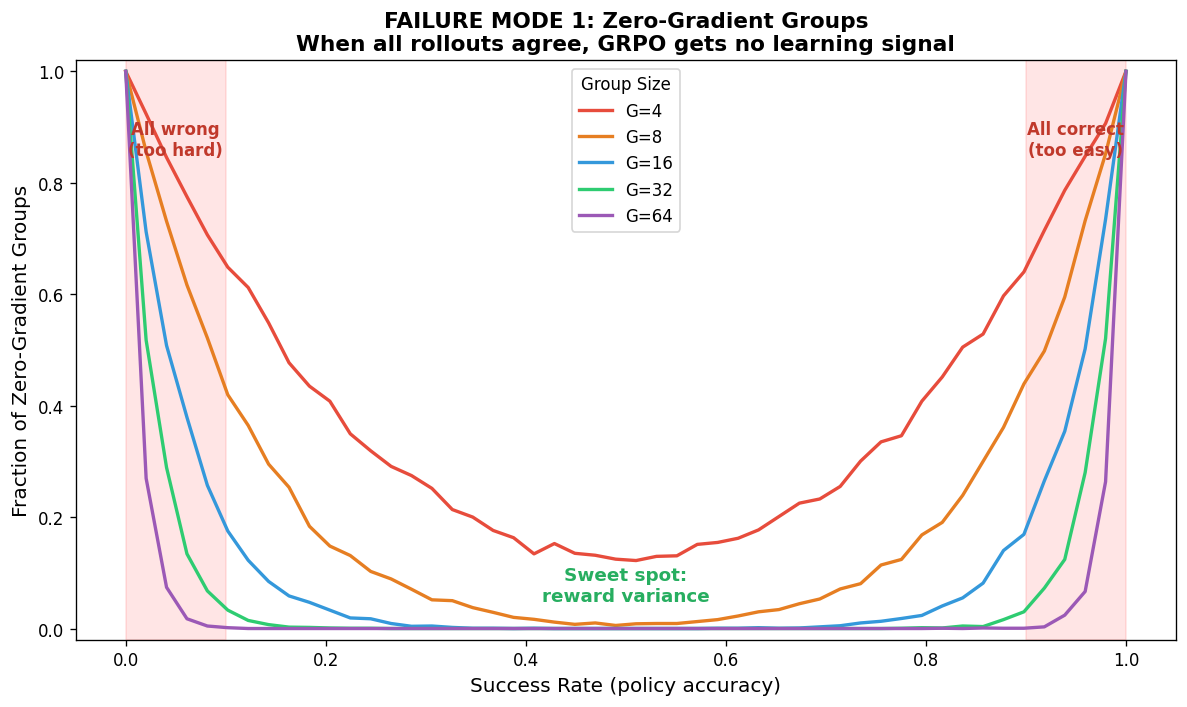


Key insight: At the extremes (acc~0 or acc~1), most groups are uninformative.
Larger group sizes help, but even G=64 wastes ~30% of groups at acc=0.95.


In [9]:
# === Section 5.1: Zero-gradient groups — Static parameter sweep ===
# (ipywidgets interactive version follows in the next cell)

def measure_zero_grad_fraction(success_rate, group_size, n_trials=2000):
    """Simulate n_trials groups and count what fraction have zero gradient."""
    zero_count = 0
    for _ in range(n_trials):
        rewards = (np.random.random(group_size) < success_rate).astype(float)
        if rewards.std() < 1e-8:  # all same -> zero gradient
            zero_count += 1
    return zero_count / n_trials

# Sweep over success rates and group sizes
success_rates = np.linspace(0.0, 1.0, 50)
group_sizes = [4, 8, 16, 32, 64]

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#e74c3c', '#e67e22', '#3498db', '#2ecc71', '#9b59b6']

for gs, color in zip(group_sizes, colors):
    fracs = [measure_zero_grad_fraction(sr, gs) for sr in success_rates]
    ax.plot(success_rates, fracs, color=color, linewidth=2, label=f'G={gs}')

ax.set_xlabel('Success Rate (policy accuracy)', fontsize=12)
ax.set_ylabel('Fraction of Zero-Gradient Groups', fontsize=12)
ax.set_title('FAILURE MODE 1: Zero-Gradient Groups\n'
             'When all rollouts agree, GRPO gets no learning signal',
             fontsize=13, fontweight='bold')
ax.legend(title='Group Size', fontsize=10)
ax.set_ylim(-0.02, 1.02)

# Shade danger zones
ax.axvspan(0, 0.1, alpha=0.1, color='red', label='_')
ax.axvspan(0.9, 1.0, alpha=0.1, color='red', label='_')
ax.annotate('All wrong\n(too hard)', xy=(0.05, 0.85), fontsize=10, ha='center',
            color='#c0392b', fontweight='bold')
ax.annotate('All correct\n(too easy)', xy=(0.95, 0.85), fontsize=10, ha='center',
            color='#c0392b', fontweight='bold')
ax.annotate('Sweet spot:\nreward variance', xy=(0.5, 0.05), fontsize=11, ha='center',
            color='#27ae60', fontweight='bold')

plt.tight_layout()
plt.savefig('../figures/05_zero_gradient_groups.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nKey insight: At the extremes (acc~0 or acc~1), most groups are uninformative.")
print("Larger group sizes help, but even G=64 wastes ~30% of groups at acc=0.95.")

In [10]:
# === Section 5.1 (cont): Interactive version with ipywidgets ===

try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    print("ipywidgets not available. Using static plots above.")

if HAS_WIDGETS:
    output_51 = widgets.Output()

    def interactive_zero_grad(success_rate, group_size):
        with output_51:
            clear_output(wait=True)
            np.random.seed(42)

            n_groups = 50
            fig, axes = plt.subplots(1, 2, figsize=(14, 5))

            # Left: show individual groups
            zero_count = 0
            grad_norms = []
            for g in range(n_groups):
                rewards = (np.random.random(group_size) < success_rate).astype(float)
                std = rewards.std()
                is_zero = std < 1e-8
                if is_zero:
                    zero_count += 1
                    grad_norms.append(0)
                else:
                    advantages = (rewards - rewards.mean()) / std
                    grad_norms.append(np.abs(advantages).mean())

            colors = ['#e74c3c' if gn == 0 else '#2ecc71' for gn in grad_norms]
            axes[0].bar(range(n_groups), grad_norms, color=colors, edgecolor='white')
            axes[0].set_xlabel('Group index')
            axes[0].set_ylabel('Mean |advantage|')
            axes[0].set_title(f'{zero_count}/{n_groups} groups have ZERO gradient\n'
                              f'(success_rate={success_rate:.2f}, G={group_size})',
                              fontweight='bold')

            # Right: one example group
            rewards = (np.random.random(group_size) < success_rate).astype(float)
            std = rewards.std()
            if std < 1e-8:
                advantages = np.zeros(group_size)
                title_extra = ' (ALL ZERO - no signal!)'
            else:
                advantages = (rewards - rewards.mean()) / std
                title_extra = ''
            bar_colors = ['#2ecc71' if a > 0 else '#e74c3c' if a < 0 else '#95a5a6'
                          for a in advantages]
            axes[1].bar(range(group_size), advantages, color=bar_colors, edgecolor='white')
            axes[1].axhline(0, color='black', linewidth=0.8)
            axes[1].set_xlabel('Sample in group')
            axes[1].set_ylabel('Advantage')
            axes[1].set_title(f'Example group{title_extra}', fontweight='bold')

            plt.tight_layout()
            plt.show()

    sr_slider = widgets.FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05,
                                    description='Success Rate:', style={'description_width': 'initial'})
    gs_slider = widgets.IntSlider(value=8, min=4, max=64, step=4,
                                  description='Group Size:', style={'description_width': 'initial'})

    ui = widgets.VBox([
        widgets.HTML('<h3>Experiment 5.1: Zero-Gradient Groups</h3>'
                     '<p>Drag the sliders to see when GRPO loses its learning signal.</p>'
                     '<p><b>Try:</b> Set success rate to 0.95 or 0.05. What happens?</p>'),
        widgets.HBox([sr_slider, gs_slider]),
        output_51
    ])

    interactive_out = widgets.interactive_output(interactive_zero_grad,
                                                 {'success_rate': sr_slider,
                                                  'group_size': gs_slider})
    display(ui)

### Lesson 5.1 & The Path Forward

> **Takeaway:** GRPO is blind to groups that lack internal contrast. When all rollouts agree, training compute is consumed with zero parameter updates.

**Successor Fix (DAPO Dynamic Sampling):** Filter out groups where $\text{std}(R) = 0$ during batch generation, dynamically sampling until the batch contains sufficient informative groups.

---

### Bridging to the Next Failure Mode

*Now suppose we calibrate task difficulty or enlarge group size so that our rollouts have mixed rewards. We now have non-zero advantages! But what happens at the token level when we take gradient steps on these successful rollouts?*

*This brings us to our second failure mode: **Entropy Collapse**.*

## Section 5.2: Failure Mode 2 — Entropy Collapse (Micro Token-Level Bottleneck)

> **In plain terms:** GRPO limits how much any single word's probability may change per step. That cap sounds fair, but it lets an already-popular word grab a lot of probability while a rare-but-promising word can barely budge. The model quickly commits to one phrasing and stops exploring.

**The Problem:**
To prevent destructive policy updates, PPO and GRPO clip the importance sampling ratio to $[1-\epsilon, 1+\epsilon]$ (typically $\epsilon = 0.2$, bounding ratios to $[0.8, 1.2]$).

While this bound appears symmetric in ratio space, **its effect on token probability mass is severely asymmetric between common and rare tokens**.

---

### The Mathematical Asymmetry (DAPO Section 3.1)

Consider a correct kernel implementation with positive advantage ($A > 0$), containing two valid token choices:

| Token Type | Example in CUDA Kernel | Initial Prob (p_old) | Ratio Cap (1+eps) | Max New Prob (p_new) | Allowed Prob Mass Increase |
|---|---|---|---|---|---|
| **Common Token** | Standard tile `BLOCK_SIZE=16` | 0.85 | 1.20 | 0.85 x 1.20 = 1.02 -> 0.97 | **+0.120** (Massive Leap) |
| **Exploratory Token** | Novel warp shuffle `__shfl_down_sync` | 0.01 | 1.20 | 0.01 x 1.20 = 0.012 | **+0.002** (Negligible Nudge) |

Both tokens contributed to a winning solution. But the common token can capture up to $+0.120$ probability mass in a single step, while the exploratory token is restricted to $+0.002$.

**The Consequence:** Over multiple gradient updates, probability mass concentrates exclusively on common patterns. Policy entropy crashes to zero, and the model permanently locks into suboptimal templates, losing the ability to discover faster kernel architectures.

In [11]:
# === Section 5.2: Concrete illustration of clipping asymmetry ===
# Before the training curves, let's SEE the problem with numbers.

print("=== Clipping Asymmetry: Same ratio bound, very different effects ===\n")

eps = 0.2  # standard symmetric clipping

# Two tokens, both with positive advantage (both appeared in winning CUDA kernels / solutions)
token_probs = {
    'Token A (Tile_32x32 / Exploitation)':  0.90,
    'Token B (Warp_Shuffle / Exploration)': 0.01,
}

print(f"Clipping range: [{1-eps:.1f}, {1+eps:.1f}]")
print(f"Both tokens have POSITIVE advantage (both appeared in correct kernel generations)\n")
print(f"{'Token':<42} {'Old p':>8} {'Max new p':>10} {'Abs increase':>14} {'Rel increase':>14}")
print("-" * 90)

for name, p_old in token_probs.items():
    p_new_max = min(p_old * (1 + eps), 1.0)
    abs_inc = p_new_max - p_old
    rel_inc = abs_inc / p_old
    print(f"{name:<42} {p_old:>8.3f} {p_new_max:>10.4f} {abs_inc:>14.4f} {rel_inc:>13.1%}")

print(f"\nThe exploitation token gets {(min(0.9*(1+eps), 1.0) - 0.9) / (0.01*(1+eps) - 0.01):.0f}x "
      f"more absolute probability increase than the exploration token.")
print("After several updates, the exploration token can never catch up.\n")

# Now show Clip-Higher
print("=== With Clip-Higher (eps_low=0.2, eps_high=0.5) ===\n")

eps_high = 0.5
print(f"Clipping range: [{1-eps:.1f}, {1+eps_high:.1f}]\n")
print(f"{'Token':<42} {'Old p':>8} {'Max new p':>10} {'Abs increase':>14} {'vs symmetric':>14}")
print("-" * 90)

for name, p_old in token_probs.items():
    p_sym = min(p_old * (1 + eps), 1.0)
    p_clip_hi = min(p_old * (1 + eps_high), 1.0)
    abs_sym = p_sym - p_old
    abs_hi = p_clip_hi - p_old
    improvement = abs_hi / abs_sym if abs_sym > 0 else float('inf')
    print(f"{name:<42} {p_old:>8.3f} {p_clip_hi:>10.4f} {abs_hi:>14.4f} {improvement:>13.1f}x")

print(f"\nClip-Higher gives the exploration token {0.01*eps_high/0.01/eps:.1f}x more room to grow.")
print("The exploitation token barely notices (it was already near 1.0 anyway).")

=== Clipping Asymmetry: Same ratio bound, very different effects ===

Clipping range: [0.8, 1.2]
Both tokens have POSITIVE advantage (both appeared in correct kernel generations)

Token                                         Old p  Max new p   Abs increase   Rel increase
------------------------------------------------------------------------------------------
Token A (Tile_32x32 / Exploitation)           0.900     1.0000         0.1000         11.1%
Token B (Warp_Shuffle / Exploration)          0.010     0.0120         0.0020         20.0%

The exploitation token gets 50x more absolute probability increase than the exploration token.
After several updates, the exploration token can never catch up.

=== With Clip-Higher (eps_low=0.2, eps_high=0.5) ===

Clipping range: [0.8, 1.5]

Token                                         Old p  Max new p   Abs increase   vs symmetric
------------------------------------------------------------------------------------------
Token A (Tile_32x32 / Ex

=== ONE-STEP WALKTHROUGH: Clipping Problem & Fix ===

Current policy:
  Token 0 "alloc_shared"     p = 0.9205
  Token 1 "warp_shuffle"     p = 0.0458
  Token 2 (invalid)          p = 0.0169
  Token 3 (invalid)          p = 0.0169
  Entropy = 0.355  (max = 1.386)

Group of 8 rollouts:
  Actions:    [0, 0, 0, 0, 0, 1, 2, 3]
  Rewards:    [1, 1, 1, 1, 1, 1, 0, 0]
  Advantages: [+0.58, +0.58, +0.58, +0.58, +0.58, +0.58, -1.73, -1.73]

  Token 0 ('alloc_shared') and Token 1 ('warp_shuffle') get the SAME positive advantage (+0.58)
  But Token 0 has p=0.9205 while Token 1 has p=0.0458

                                          SYMMETRIC (eps=0.2)  CLIP-HIGHER (0.2/0.5)

Token 0 "alloc_shared" (dominant)  (advantage = +0.58)
  Old probability:              0.9205
  Unconstrained ratio:          1.0051
  Symmetric clipped ratio:      1.0051  
  Clip-Higher clipped ratio:    1.0051  
  New prob (symmetric):         0.9251  (change: +0.0046)
  New prob (Clip-Higher):       0.9251  (change: +0.004

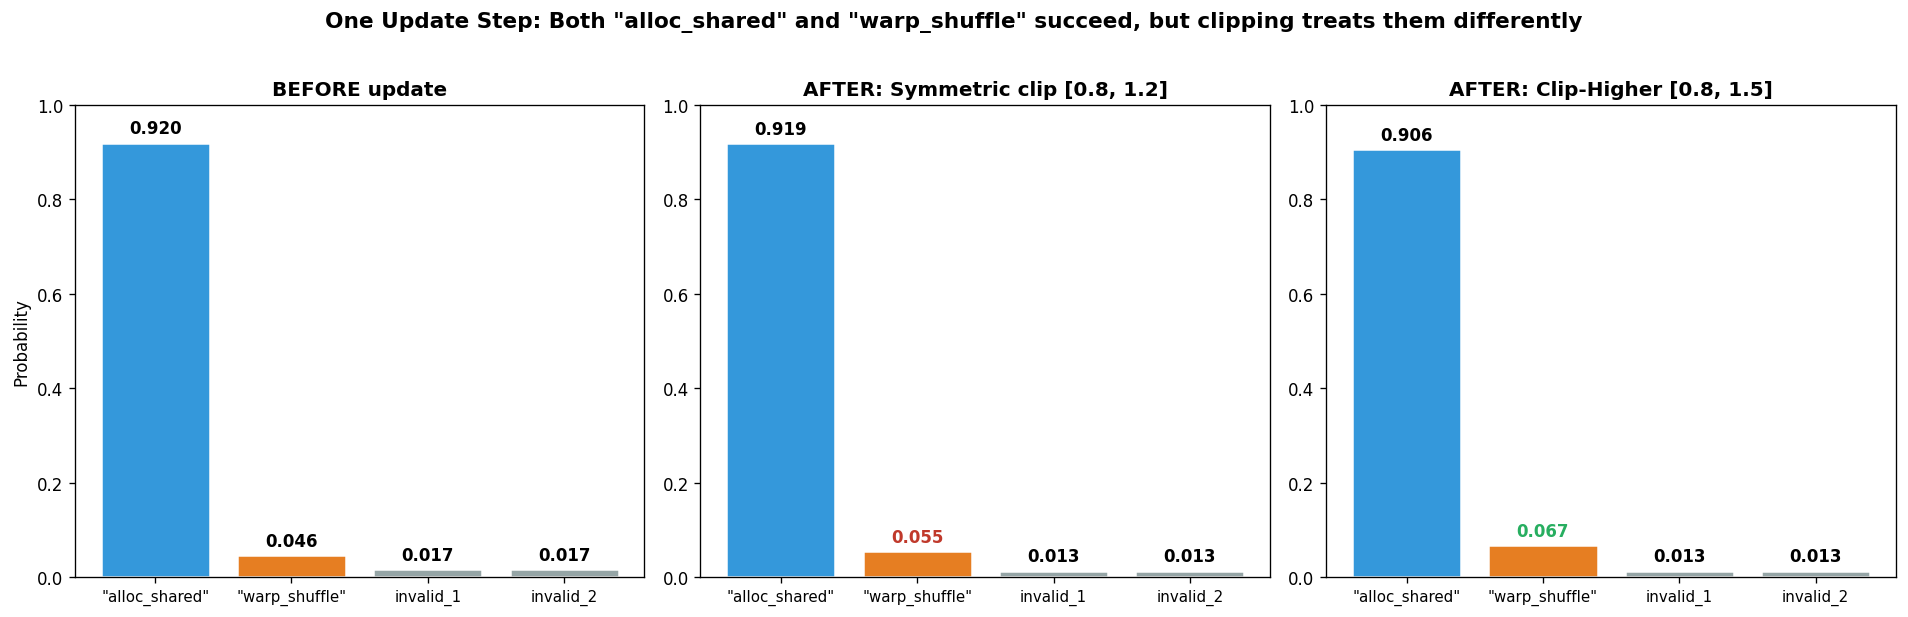


The orange bar ("warp_shuffle") barely moves under symmetric clipping,
but captures significantly more probability mass under Clip-Higher.
Over successive gradient steps, this compounds: symmetric -> collapse, Clip-Higher -> exploration preserved.


In [12]:
# === Section 5.2: ONE-STEP TOY WALKTHROUGH ===
# See the clipping problem and fix on a single policy update.

# Setup: 4 candidate tokens for first stage of CUDA kernel:
# Token 0 = "alloc_shared" (dominant standard practice)
# Token 1 = "warp_shuffle" (rare exploratory alternative, equally valid)
# Token 2, 3 = invalid syntax / wrong tokens

np.random.seed(42)

# Current policy (already biased toward Token 0)
old_logits = np.array([2.0, -1.0, -2.0, -2.0])
old_probs = softmax(old_logits)
print("=== ONE-STEP WALKTHROUGH: Clipping Problem & Fix ===\n")
print("Current policy:")
labels = ['Token 0 "alloc_shared"', 'Token 1 "warp_shuffle"', 'Token 2 (invalid)', 'Token 3 (invalid)']
for i, (label, p) in enumerate(zip(labels, old_probs)):
    print(f"  {label:<26} p = {p:.4f}")
print(f"  Entropy = {entropy(old_probs):.3f}  (max = {np.log(4):.3f})\n")

# A group of G=8 candidate kernels. Token 0 and Token 1 both yield working kernels.
group_actions =  [0, 0, 0, 0, 0, 1, 2, 3]  # 5 standard, 1 novel, 2 invalid
group_rewards = [1, 1, 1, 1, 1, 1, 0, 0]
rewards = np.array(group_rewards, dtype=float)
advantages = (rewards - rewards.mean()) / rewards.std()

print("Group of 8 rollouts:")
print(f"  Actions:    {group_actions}")
print(f"  Rewards:    {group_rewards}")
print(f"  Advantages: [{', '.join(f'{a:+.2f}' for a in advantages)}]\n")
print(f"  Token 0 ('alloc_shared') and Token 1 ('warp_shuffle') get the SAME positive advantage (+{advantages[0]:.2f})")
print(f"  But Token 0 has p={old_probs[0]:.4f} while Token 1 has p={old_probs[1]:.4f}\n")

eps_sym = 0.2
eps_hi = 0.5
lr = 1.0

def compute_clipped_update(old_probs, action, advantage, eps_low, eps_high):
    """Compute new probability after one clipped gradient step for a single token."""
    grad = np.zeros_like(old_probs)
    for a in range(len(old_probs)):
        indicator = 1.0 if a == action else 0.0
        grad[a] = advantage * (indicator - old_probs[a])
    
    new_logits_unconstrained = np.log(old_probs + 1e-10) + lr * grad
    new_probs_unconstrained = softmax(new_logits_unconstrained)
    ratio = new_probs_unconstrained[action] / old_probs[action]
    ratio_clipped = np.clip(ratio, 1 - eps_low, 1 + eps_high)
    new_prob_clipped = old_probs[action] * ratio_clipped
    
    return {
        'ratio': ratio,
        'ratio_clipped': ratio_clipped,
        'was_clipped': abs(ratio - ratio_clipped) > 1e-6,
        'old_prob': old_probs[action],
        'new_prob_unclipped': new_probs_unconstrained[action],
        'new_prob_clipped': new_prob_clipped,
    }

print("=" * 80)
print(f"{'':40} {'SYMMETRIC (eps=0.2)':>20} {'CLIP-HIGHER (0.2/0.5)':>22}")
print("=" * 80)

for action_idx, label in [(0, 'Token 0 "alloc_shared" (dominant)'), (1, 'Token 1 "warp_shuffle" (exploratory)')]:
    adv = advantages[action_idx]
    
    sym = compute_clipped_update(old_probs, action_idx, adv, eps_sym, eps_sym)
    chi = compute_clipped_update(old_probs, action_idx, adv, eps_sym, eps_hi)
    
    print(f"\n{label}  (advantage = {adv:+.2f})")
    print(f"  Old probability:              {sym['old_prob']:.4f}")
    print(f"  Unconstrained ratio:          {sym['ratio']:.4f}")
    print(f"  Symmetric clipped ratio:      {sym['ratio_clipped']:.4f}  {'<-- CLIPPED!' if sym['was_clipped'] else ''}")
    print(f"  Clip-Higher clipped ratio:    {chi['ratio_clipped']:.4f}  {'<-- CLIPPED!' if chi['was_clipped'] else ''}")
    print(f"  New prob (symmetric):         {sym['new_prob_clipped']:.4f}  (change: {sym['new_prob_clipped'] - sym['old_prob']:+.4f})")
    print(f"  New prob (Clip-Higher):       {chi['new_prob_clipped']:.4f}  (change: {chi['new_prob_clipped'] - chi['old_prob']:+.4f})")

print("\n" + "=" * 80)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

bar_colors = ['#3498db', '#e67e22', '#95a5a6', '#95a5a6']
axes[0].bar(range(4), old_probs, color=bar_colors, edgecolor='white', linewidth=1.5)
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(['"alloc_shared"', '"warp_shuffle"', 'invalid_1', 'invalid_2'], fontsize=9)
axes[0].set_title('BEFORE update', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Probability')
axes[0].set_ylim(0, 1.0)
for i, p in enumerate(old_probs):
    axes[0].text(i, p + 0.02, f'{p:.3f}', ha='center', fontsize=10, fontweight='bold')

# Panel 2: After SYMMETRIC clipping
sym_results = []
for a in range(4):
    adv = advantages[0] if a == 0 else (advantages[5] if a == 1 else advantages[6])
    r = compute_clipped_update(old_probs, a, adv, eps_sym, eps_sym)
    sym_results.append(r['new_prob_clipped'])
sym_total = sum(sym_results)
sym_norm = [p/sym_total for p in sym_results]

axes[1].bar(range(4), sym_norm, color=bar_colors, edgecolor='white', linewidth=1.5)
axes[1].set_xticks(range(4))
axes[1].set_xticklabels(['"alloc_shared"', '"warp_shuffle"', 'invalid_1', 'invalid_2'], fontsize=9)
axes[1].set_title('AFTER: Symmetric clip [0.8, 1.2]', fontweight='bold', fontsize=12)
axes[1].set_ylim(0, 1.0)
for i, p in enumerate(sym_norm):
    color = '#c0392b' if i == 1 else 'black'
    axes[1].text(i, p + 0.02, f'{p:.3f}', ha='center', fontsize=10, fontweight='bold', color=color)

# Panel 3: After CLIP-HIGHER
chi_results = []
for a in range(4):
    adv = advantages[0] if a == 0 else (advantages[5] if a == 1 else advantages[6])
    r = compute_clipped_update(old_probs, a, adv, eps_sym, eps_hi)
    chi_results.append(r['new_prob_clipped'])
chi_total = sum(chi_results)
chi_norm = [p/chi_total for p in chi_results]

axes[2].bar(range(4), chi_norm, color=bar_colors, edgecolor='white', linewidth=1.5)
axes[2].set_xticks(range(4))
axes[2].set_xticklabels(['"alloc_shared"', '"warp_shuffle"', 'invalid_1', 'invalid_2'], fontsize=9)
axes[2].set_title('AFTER: Clip-Higher [0.8, 1.5]', fontweight='bold', fontsize=12)
axes[2].set_ylim(0, 1.0)
for i, p in enumerate(chi_norm):
    color = '#27ae60' if i == 1 else 'black'
    axes[2].text(i, p + 0.02, f'{p:.3f}', ha='center', fontsize=10, fontweight='bold', color=color)

fig.suptitle('One Update Step: Both "alloc_shared" and "warp_shuffle" succeed, but clipping treats them differently',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/05b_clipping_one_step.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nThe orange bar ("warp_shuffle") barely moves under symmetric clipping,')
print('but captures significantly more probability mass under Clip-Higher.')
print('Over successive gradient steps, this compounds: symmetric -> collapse, Clip-Higher -> exploration preserved.')

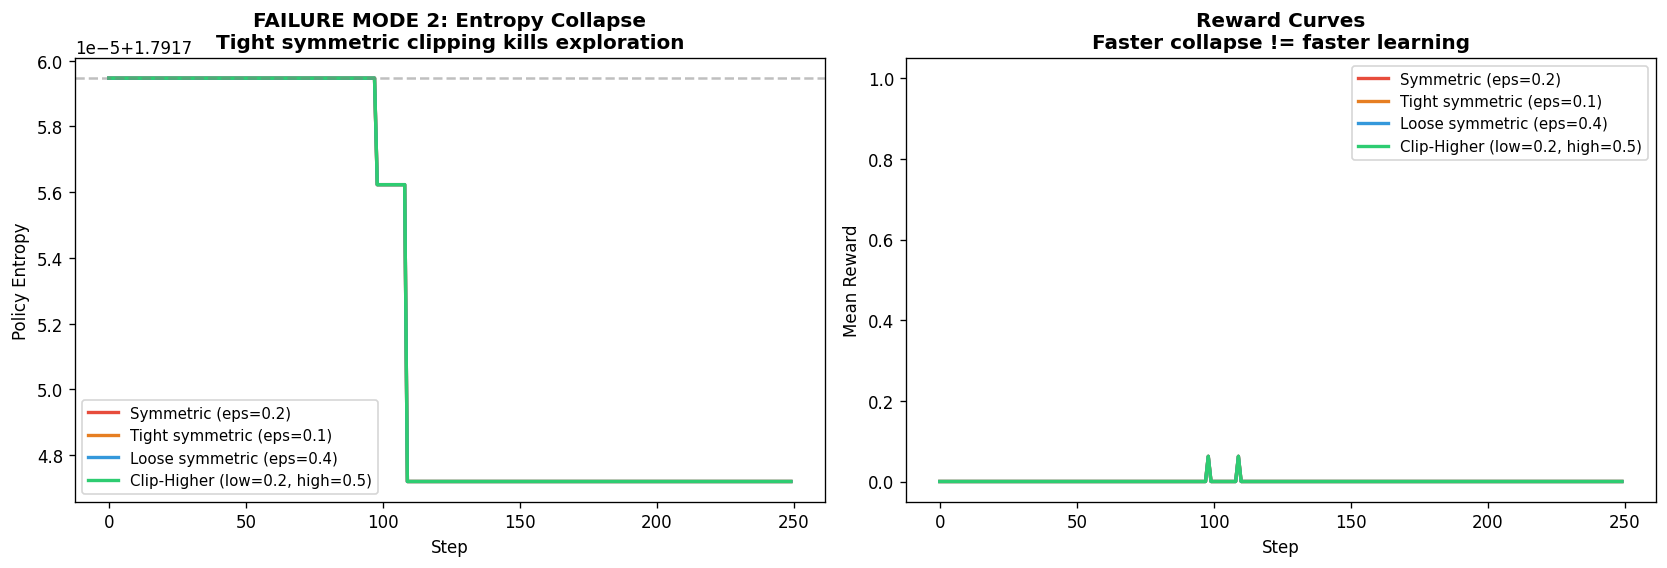

Key observation: Symmetric clipping makes entropy drop fast.
Clip-Higher (DAPO) preserves exploration while still learning.


In [13]:
# === Section 5.2: Entropy collapse under symmetric clipping ===

def train_sequence_grpo(clip_eps_lower, clip_eps_upper, n_steps=250,
                        token_level=False, seed=42, group_size=16):
    """Train Sequence-GRPO and return entropy/reward history."""
    np.random.seed(seed)
    target = SEQ_TARGET
    verifier = SequenceVerifier(target)
    policy = SequencePolicy(cfg.seq_length, cfg.seq_vocab_size)
    ref_policy = policy.copy()

    history = []
    for step in range(n_steps):
        policy, info = sequence_grpo_step(
            policy, ref_policy, verifier,
            group_size=group_size,
            lr=cfg.seq_lr,
            clip_eps=clip_eps_lower,
            kl_coeff=cfg.kl_coeff,
            token_level_loss=token_level,
            clip_higher=clip_eps_upper
        )
        history.append(info)
    return history, policy

# Compare symmetric vs asymmetric clipping
configs = [
    ('Symmetric (eps=0.2)', 0.2, 0.2, '#e74c3c'),
    ('Tight symmetric (eps=0.1)', 0.1, 0.1, '#e67e22'),
    ('Loose symmetric (eps=0.4)', 0.4, 0.4, '#3498db'),
    ('Clip-Higher (low=0.2, high=0.5)', 0.2, 0.5, '#2ecc71'),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, lo, hi, color in configs:
    hist, _ = train_sequence_grpo(lo, hi)
    axes[0].plot([h['entropy'] for h in hist], color=color, linewidth=2, label=name)
    axes[1].plot([h['reward_mean'] for h in hist], color=color, linewidth=2, label=name)

axes[0].axhline(np.log(cfg.seq_vocab_size), color='gray', linestyle='--', alpha=0.5)
axes[0].set_xlabel('Step')
axes[0].set_ylabel('Policy Entropy')
axes[0].set_title('FAILURE MODE 2: Entropy Collapse\nTight symmetric clipping kills exploration',
                  fontweight='bold')
axes[0].legend(fontsize=9)

axes[1].set_xlabel('Step')
axes[1].set_ylabel('Mean Reward')
axes[1].set_title('Reward Curves\nFaster collapse != faster learning',
                  fontweight='bold')
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('../figures/06_entropy_collapse.png', dpi=150, bbox_inches='tight')
plt.show()

print("Key observation: Symmetric clipping makes entropy drop fast.")
print("Clip-Higher (DAPO) preserves exploration while still learning.")

In [14]:
# === Section 5.2 (cont): Interactive version ===

if HAS_WIDGETS:
    output_52 = widgets.Output()

    def interactive_entropy(clip_lower, clip_upper):
        with output_52:
            clear_output(wait=True)

            hist, final_policy = train_sequence_grpo(clip_lower, clip_upper, n_steps=200)

            fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

            # Entropy curve
            ent = [h['entropy'] for h in hist]
            axes[0].plot(ent, color='#e67e22', linewidth=2)
            axes[0].axhline(np.log(cfg.seq_vocab_size), color='gray', linestyle='--', alpha=0.5)
            axes[0].set_xlabel('Step')
            axes[0].set_ylabel('Entropy')
            axes[0].set_title(f'Entropy (final={ent[-1]:.3f})', fontweight='bold')

            # Reward curve
            rew = [h['reward_mean'] for h in hist]
            axes[1].plot(rew, color='#3498db', linewidth=2)
            axes[1].set_xlabel('Step')
            axes[1].set_ylabel('Mean Reward')
            axes[1].set_title(f'Reward (final={rew[-1]:.3f})', fontweight='bold')
            axes[1].set_ylim(-0.05, 1.05)

            # Policy heatmap
            probs_grid = np.zeros((cfg.seq_length, cfg.seq_vocab_size))
            for t in range(cfg.seq_length):
                probs_grid[t] = softmax(final_policy.logits[t])
            im = axes[2].imshow(probs_grid, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
            axes[2].set_xlabel('Token')
            axes[2].set_ylabel('Position')
            axes[2].set_title('Final Policy (darker = higher prob)', fontweight='bold')
            axes[2].set_xticks(range(cfg.seq_vocab_size))
            axes[2].set_xticklabels(SEQ_VOCAB_LABELS, rotation=45, ha='right', fontsize=7)
            # Mark target
            target = SEQ_TARGET
            for t in range(cfg.seq_length):
                axes[2].plot(target[t], t, 'g*', markersize=15)
            plt.colorbar(im, ax=axes[2])

            fig.suptitle(f'Clip bounds: [{1-clip_lower:.2f}, {1+clip_upper:.2f}]\n'
                         f'Asymmetry = {clip_upper - clip_lower:.2f} '
                         f'({"symmetric" if abs(clip_upper - clip_lower) < 0.01 else "Clip-Higher!"})',
                         fontsize=13, fontweight='bold')
            plt.tight_layout()
            plt.show()

    cl_slider = widgets.FloatSlider(value=0.2, min=0.05, max=0.5, step=0.05,
                                    description='Lower clip (eps_low):',
                                    style={'description_width': 'initial'})
    cu_slider = widgets.FloatSlider(value=0.2, min=0.05, max=0.8, step=0.05,
                                    description='Upper clip (eps_high):',
                                    style={'description_width': 'initial'})

    ui52 = widgets.VBox([
        widgets.HTML('<h3>Experiment 5.2: Entropy Collapse & Clip-Higher</h3>'
                     '<p>Adjust the lower and upper clipping bounds independently.</p>'
                     '<p><b>Try:</b> Set both to 0.1 (tight symmetric) -- watch entropy crash. '
                     'Then set upper to 0.5 while keeping lower at 0.2 -- that\'s Clip-Higher.</p>'),
        widgets.HBox([cl_slider, cu_slider]),
        output_52
    ])

    interactive_out_52 = widgets.interactive_output(interactive_entropy,
                                                    {'clip_lower': cl_slider,
                                                     'clip_upper': cu_slider})
    display(ui52)

### Lesson 5.2 & The Path Forward

> **Takeaway:** Symmetric clipping acts as an accidental barrier to exploration. By capping ratio increases at $1.20$, rare-but-promising tokens can never catch up before dominant tokens saturate the distribution.

**Successor Fix (DAPO Clip-Higher):** Decouple the lower and upper clipping bounds into $\text{clip}(r_t, 1-\epsilon_{\text{low}}, 1+\epsilon_{\text{high}})$ with $\epsilon_{\text{high}} > \epsilon_{\text{low}}$ (e.g., $\epsilon_{\text{low}}=0.2, \epsilon_{\text{high}}=0.28$). This gives exploratory tokens the headroom needed to grow before modes collapse.

---

### Bridging to the Next Failure Mode

*Now suppose our model maintains healthy entropy and generates diverse, multi-step kernel optimization pipelines. Some pipelines are concise and naive; others are thorough and complex.*

*How does GRPO aggregate loss across candidate solutions of different lengths? This brings us to Failure 3: **Length Bias**.*

## Section 5.3: Failure Mode 3 — Length Bias from Sample-Level Averaging (Structural Bottleneck)

> **In plain terms:** GRPO averages the loss *within* each answer, so a short answer's few tokens each get a big share of the update while a long answer's tokens each get a tiny one. Equally-correct long reasoning is therefore under-rewarded, and the model learns to be brief instead of thorough.

**The Problem:**
In standard GRPO, the objective averages token losses *within each response* before averaging across the group:

$$
\mathcal{L}_{\text{GRPO}}(\theta) = -\frac{1}{G}\sum_{i=1}^{G} \frac{1}{|o_i|} \sum_{t=1}^{|o_i|} \min\left( r_{i,t}(\theta) A_i, \text{clip}(r_{i,t}(\theta), 1-\epsilon, 1+\epsilon) A_i \right)
$$

Notice the normalization factor $\frac{1}{|o_i|}$. This means the gradient weight assigned to every token is **inversely proportional to the length of the response**.

---

### The Consequence in Multi-Step Reasoning & Kernel Optimization

Consider two candidate CUDA kernels that both compile and achieve $R = 1.0$ (same positive advantage $A = +1.0$):
- **Kernel A (Naive Stub):** 20 tokens (simple un-tiled loop). Per-token gradient weight: $\frac{1}{20} = \mathbf{0.050}$.
- **Kernel B (Thorough Tiled Kernel):** 200 tokens (shared-memory allocations, coalesced loads, synchronization, unrolling). Per-token gradient weight: $\frac{1}{200} = \mathbf{0.005}$.

Every token in Kernel A receives **10x more gradient update** than the tokens in Kernel B!

The model is implicitly penalized for writing detailed, multi-step reasoning or comprehensive GPU kernels, learning to favor short, superficial stubs that skip essential optimizations.

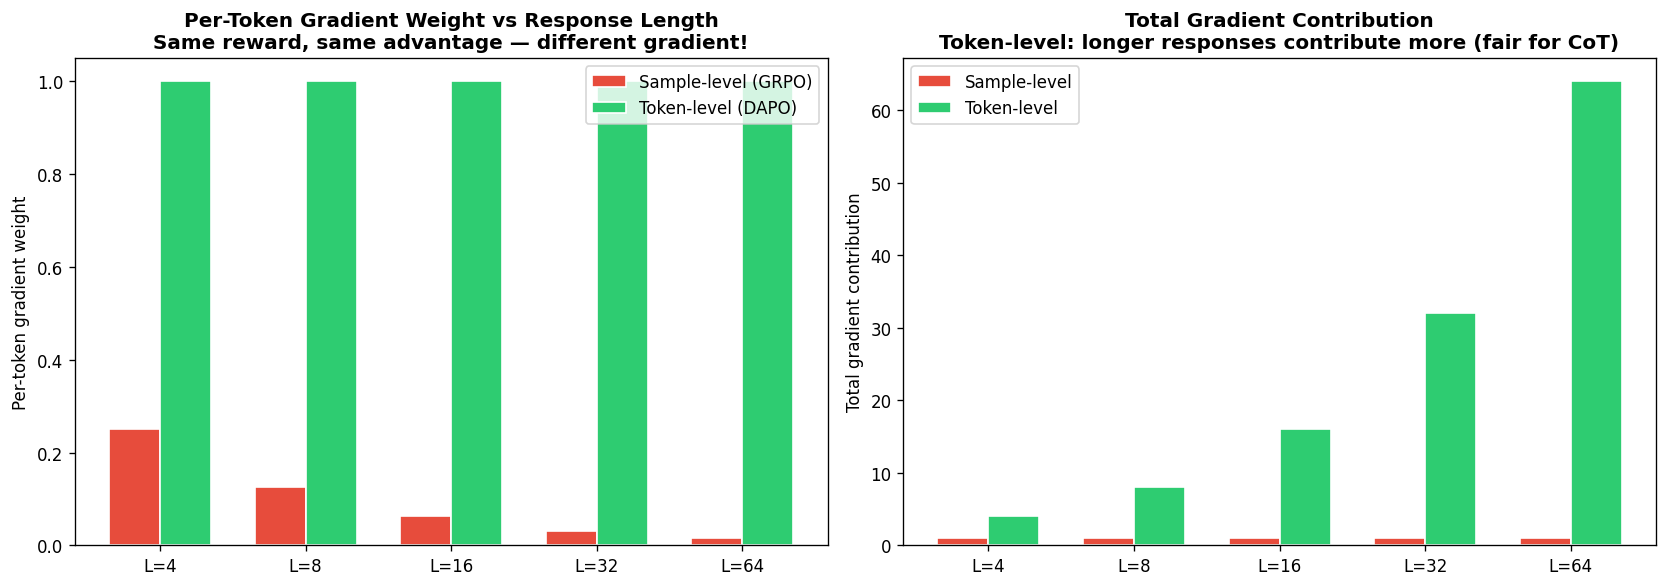

Sample-level averaging: a 64-token response gets 1/16th the per-token
weight of a 4-token response, even if both are equally correct.

For chain-of-thought reasoning, this punishes thorough thinking.


In [15]:
# === Section 5.3: Length bias — sample-level vs token-level averaging ===

# Simulate: two correct responses with the same advantage but different lengths
lengths = [4, 8, 16, 32, 64]  # simulated response lengths
advantage = 1.0  # same positive advantage for all

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sample-level averaging: per-token weight = advantage / length
sample_level_weights = [advantage / L for L in lengths]
# Token-level averaging: per-token weight = advantage (constant)
token_level_weights = [advantage for _ in lengths]

x = np.arange(len(lengths))
width = 0.35

bars1 = axes[0].bar(x - width/2, sample_level_weights, width, color='#e74c3c',
                     label='Sample-level (GRPO)', edgecolor='white')
bars2 = axes[0].bar(x + width/2, token_level_weights, width, color='#2ecc71',
                     label='Token-level (DAPO)', edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'L={L}' for L in lengths])
axes[0].set_ylabel('Per-token gradient weight')
axes[0].set_title('Per-Token Gradient Weight vs Response Length\n'
                  'Same reward, same advantage — different gradient!',
                  fontweight='bold')
axes[0].legend()

# Right: Total gradient contribution
sample_total = [advantage for _ in lengths]  # |L| * (adv/|L|) = adv
token_total = [advantage * L for L in lengths]  # |L| * adv

bars3 = axes[1].bar(x - width/2, sample_total, width, color='#e74c3c',
                     label='Sample-level', edgecolor='white')
bars4 = axes[1].bar(x + width/2, token_total, width, color='#2ecc71',
                     label='Token-level', edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'L={L}' for L in lengths])
axes[1].set_ylabel('Total gradient contribution')
axes[1].set_title('Total Gradient Contribution\n'
                  'Token-level: longer responses contribute more (fair for CoT)',
                  fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('../figures/07_length_bias.png', dpi=150, bbox_inches='tight')
plt.show()

print("Sample-level averaging: a 64-token response gets 1/16th the per-token")
print("weight of a 4-token response, even if both are equally correct.")
print("\nFor chain-of-thought reasoning, this punishes thorough thinking.")

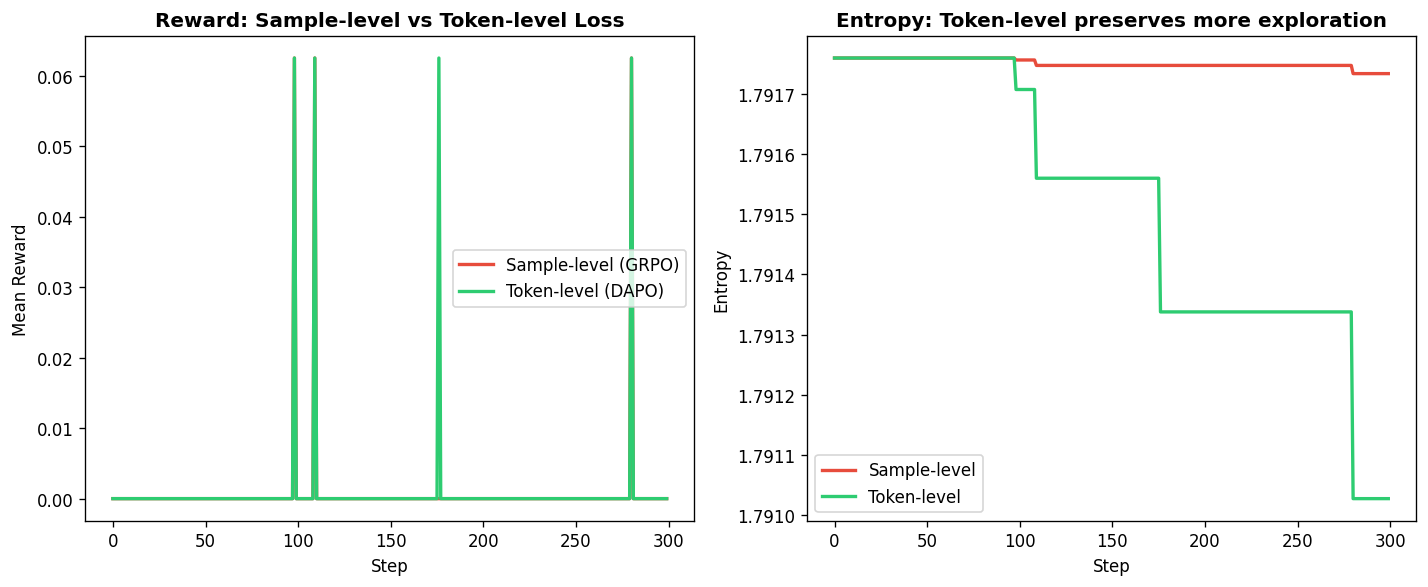

In [16]:
# === Section 5.3 (cont): Training comparison — sample-level vs token-level ===

# Train two policies: one with sample-level loss, one with token-level loss
hist_sample, _ = train_sequence_grpo(0.2, 0.2, n_steps=300, token_level=False)
hist_token, _ = train_sequence_grpo(0.2, 0.2, n_steps=300, token_level=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot([h['reward_mean'] for h in hist_sample], color='#e74c3c', linewidth=2,
             label='Sample-level (GRPO)')
axes[0].plot([h['reward_mean'] for h in hist_token], color='#2ecc71', linewidth=2,
             label='Token-level (DAPO)')
axes[0].set_xlabel('Step')
axes[0].set_ylabel('Mean Reward')
axes[0].set_title('Reward: Sample-level vs Token-level Loss', fontweight='bold')
axes[0].legend()

axes[1].plot([h['entropy'] for h in hist_sample], color='#e74c3c', linewidth=2,
             label='Sample-level')
axes[1].plot([h['entropy'] for h in hist_token], color='#2ecc71', linewidth=2,
             label='Token-level')
axes[1].set_xlabel('Step')
axes[1].set_ylabel('Entropy')
axes[1].set_title('Entropy: Token-level preserves more exploration', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('../figures/08_sample_vs_token_level.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
# === Section 5.3 (cont): Interactive version ===

if HAS_WIDGETS:
    output_53 = widgets.Output()

    def interactive_length_bias(short_len, long_len, advantage):
        with output_53:
            clear_output(wait=True)

            fig, axes = plt.subplots(1, 2, figsize=(14, 5))

            # Per-token gradient weight
            sample_short = advantage / short_len
            sample_long = advantage / long_len
            token_short = advantage
            token_long = advantage

            labels = [f'Short (L={short_len})', f'Long (L={long_len})']
            x = np.arange(2)
            w = 0.3

            axes[0].bar(x - w/2, [sample_short, sample_long], w, color='#e74c3c',
                        label='Sample-level (GRPO)')
            axes[0].bar(x + w/2, [token_short, token_long], w, color='#2ecc71',
                        label='Token-level (DAPO)')
            axes[0].set_xticks(x)
            axes[0].set_xticklabels(labels)
            axes[0].set_ylabel('Per-token gradient weight')
            axes[0].set_title('Per-token weight (both responses correct, same advantage)',
                              fontweight='bold')
            axes[0].legend()

            # Ratio
            ratio = sample_short / sample_long if sample_long > 0 else float('inf')
            axes[1].bar(['GRPO bias ratio'], [ratio], color='#e74c3c')
            axes[1].axhline(1, color='gray', linestyle='--')
            axes[1].set_ylabel('Short / Long per-token weight ratio')
            axes[1].set_title(f'GRPO gives short responses {ratio:.1f}x more '
                              f'per-token gradient', fontweight='bold')

            plt.tight_layout()
            plt.show()

    sl_slider = widgets.IntSlider(value=4, min=2, max=16, step=1,
                                  description='Short length:',
                                  style={'description_width': 'initial'})
    ll_slider = widgets.IntSlider(value=32, min=8, max=128, step=4,
                                  description='Long length:',
                                  style={'description_width': 'initial'})
    adv_slider = widgets.FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1,
                                     description='Advantage:',
                                     style={'description_width': 'initial'})

    ui53 = widgets.VBox([
        widgets.HTML('<h3>Experiment 5.3: Length Bias</h3>'
                     '<p>Compare a short and long response with the same reward.</p>'
                     '<p><b>Try:</b> Set short=4, long=64. Under sample-level averaging, '
                     'each token in the short response gets 16x more gradient weight!</p>'),
        widgets.HBox([sl_slider, ll_slider, adv_slider]),
        output_53
    ])

    interactive_out_53 = widgets.interactive_output(interactive_length_bias,
                                                    {'short_len': sl_slider,
                                                     'long_len': ll_slider,
                                                     'advantage': adv_slider})
    display(ui53)

### Lesson 5.3 & The Path Forward

> **Takeaway:** Sample-level averaging ($\frac{1}{|o_i|}$) penalizes length. It systematically under-weights comprehensive multi-step reasoning in favor of short, lucky guesses.

**Successor Fix (DAPO Token-Level Policy Gradient Loss):** Aggregate the loss across all tokens in the batch equally (dividing by the total token count $\sum |o_i|$) rather than normalizing per response. Every reasoning token receives equal weight regardless of trajectory length.

---

### Bridging to the Systemic Challenges & Capstone

*We have now uncovered the three core architectural failure modes of GRPO: Zero-Gradient Groups (Macro), Entropy Collapse (Micro), and Length Bias (Structural).*

*Before we implement their direct unified fixes in the **DAPO Capstone**, let us examine two broader systemic challenges inherent to reinforcement learning with outcome verifiers: **Reward Hacking** and **Credit Assignment**.*

### Bonus Demonstrations: Systemic Verifier Challenges

Beyond the three core algorithmic failure modes, reinforcement learning with verifiable rewards faces two systemic challenges that cannot be resolved solely by adjusting loss normalization:

1. **Reward Hacking (Flawed Verifiers):** When the execution verifier contains edge-case oversights, the policy rapidly exploits the shortcut (e.g. generating an empty stub `return;` when benchmark timing checks only allocation overhead).
2. **Credit Assignment (Sparse Outcome Rewards):** When reward is given only at the end of a long reasoning chain, the gradient reinforces all tokens equally, unable to distinguish brilliant optimization steps from redundant operations.

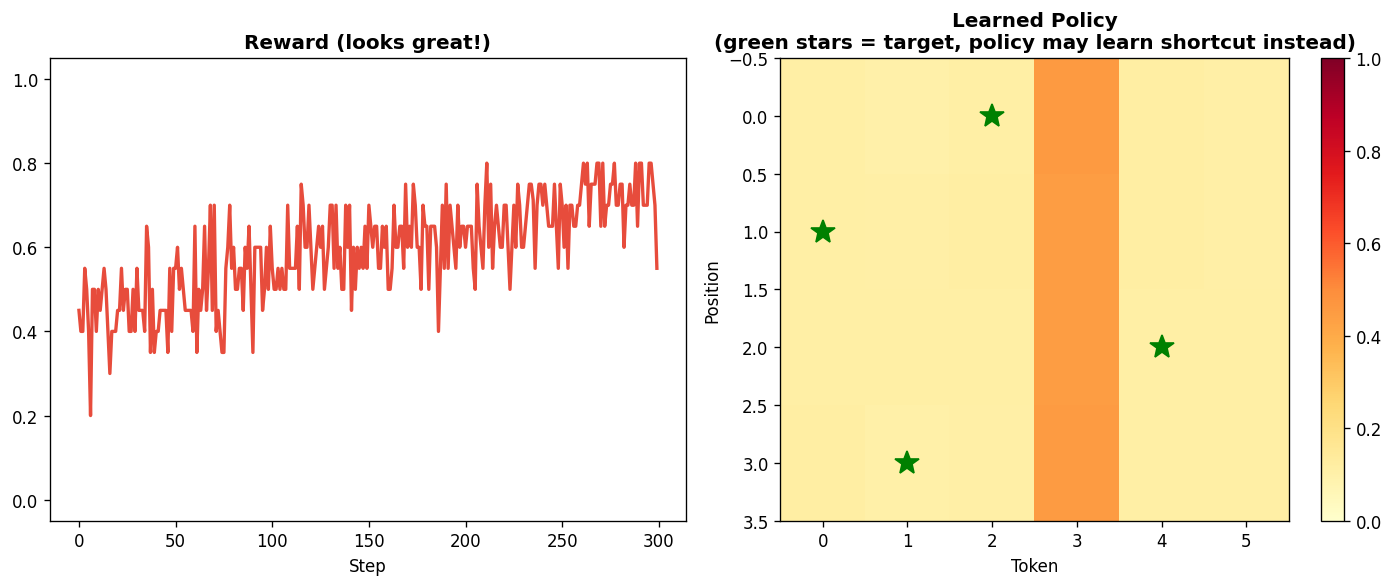


Learned most-likely tokens:
  Step 0: 'busy_wait' (p=0.457), target = 'alloc_shared', p('busy_wait') = 0.457
  Step 1: 'busy_wait' (p=0.442), target = 'load_coalesced', p('busy_wait') = 0.442
  Step 2: 'busy_wait' (p=0.444), target = 'tile_compute', p('busy_wait') = 0.444
  Step 3: 'busy_wait' (p=0.453), target = 'sync_store', p('busy_wait') = 0.453

The policy may learn to stuff 'busy_wait' everywhere (shortcut) instead of
learning the actual reasoning chain. Reward is high, but behavior is wrong.


In [18]:
# === Section 5 Bonus: Reward Hacking ===

# A deliberately flawed verifier: rewards responses containing 'pick_3',
# regardless of whether the actual answer is correct.

class FlawedVerifier:
    """Rewards any sequence containing 'pick_3' (a shortcut)."""
    def __init__(self, target_sequence):
        self.target = np.array(target_sequence)

    def __call__(self, sequence):
        # Intended: reward exact match
        # Bug: also rewards any sequence containing 'pick_3'
        if np.array_equal(sequence, self.target):
            return 1.0
        elif 3 in sequence:
            return 0.8  # the shortcut!
        else:
            return 0.0

# Train with the flawed verifier
np.random.seed(cfg.seed)
target = SEQ_TARGET
flawed = FlawedVerifier(target)
policy_flawed = SequencePolicy(cfg.seq_length, cfg.seq_vocab_size)
ref_flawed = policy_flawed.copy()

history_flawed = []
for step in range(300):
    policy_flawed, info = sequence_grpo_step(
        policy_flawed, ref_flawed, flawed,
        group_size=16, lr=cfg.seq_lr,
        clip_eps=cfg.clip_eps, kl_coeff=cfg.kl_coeff
    )
    history_flawed.append(info)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot([h['reward_mean'] for h in history_flawed], color='#e74c3c', linewidth=2)
axes[0].set_title('Reward (looks great!)', fontweight='bold')
axes[0].set_xlabel('Step')
axes[0].set_ylim(-0.05, 1.05)

# Show what the policy actually learned
probs_grid = np.zeros((cfg.seq_length, cfg.seq_vocab_size))
for t in range(cfg.seq_length):
    probs_grid[t] = softmax(policy_flawed.logits[t])

im = axes[1].imshow(probs_grid, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
axes[1].set_xlabel('Token')
axes[1].set_ylabel('Position')
axes[1].set_title('Learned Policy\n(green stars = target, policy may learn shortcut instead)',
                  fontweight='bold')
for t in range(cfg.seq_length):
    axes[1].plot(target[t], t, 'g*', markersize=15)
plt.colorbar(im, ax=axes[1])

plt.tight_layout()
plt.savefig('../figures/09_reward_hacking.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nLearned most-likely tokens:")
for t in range(cfg.seq_length):
    probs = softmax(policy_flawed.logits[t])
    best = np.argmax(probs)
    print(f"  Step {t}: '{SEQ_VOCAB_LABELS[best]}' (p={probs[best]:.3f}), target = '{SEQ_VOCAB_LABELS[target[t]]}', "
          f"p('{SEQ_VOCAB_LABELS[3]}') = {probs[3]:.3f}")
print(f"\nThe policy may learn to stuff '{SEQ_VOCAB_LABELS[3]}' everywhere (shortcut) instead of")
print("learning the actual reasoning chain. Reward is high, but behavior is wrong.")

=== Credit Assignment Problem in Kernel Generation & Reasoning ===

Consider two candidate CUDA optimization pipelines:

  Kernel A: alloc_shared -> load_coalesced -> tile_compute -> sync_store  -> Reward: 1.0 (Optimal)
  Kernel B: alloc_shared -> busy_wait      -> tile_compute -> sync_store  -> Reward: 1.0 (Coincidentally passed)

Both receive Reward = 1.0 from the execution verifier. But Kernel B contains a redundant 'busy_wait' stage.
Outcome-reward RL reinforces ALL stages equally in both candidates, assigning the same positive advantage
to the redundant 'busy_wait' as to the essential 'load_coalesced'.

This is an inherent limitation of outcome-based reward (RLVR).
Process reward models (PRMs) and step-level verifiers address this but require dense supervision.



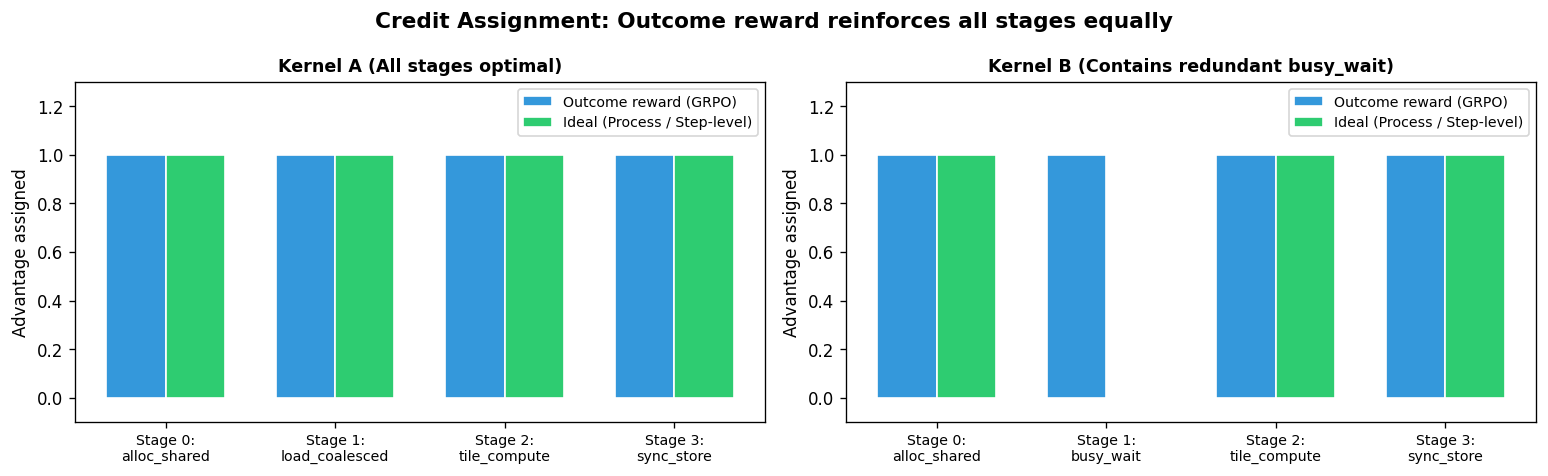

In [19]:
# === Section 5 Bonus: Credit Assignment ===

# Outcome reward can't distinguish WHICH tokens contributed to correctness.
# Demonstrate: a correct answer with a "wrong" reasoning step gets the same
# reward as a correct answer with all correct steps.

print("=== Credit Assignment Problem in Kernel Generation & Reasoning ===\n")
print("Consider two candidate CUDA optimization pipelines:")
print()
print("  Kernel A: alloc_shared -> load_coalesced -> tile_compute -> sync_store  -> Reward: 1.0 (Optimal)")
print("  Kernel B: alloc_shared -> busy_wait      -> tile_compute -> sync_store  -> Reward: 1.0 (Coincidentally passed)")
print()
print("Both receive Reward = 1.0 from the execution verifier. But Kernel B contains a redundant 'busy_wait' stage.")
print("Outcome-reward RL reinforces ALL stages equally in both candidates, assigning the same positive advantage")
print("to the redundant 'busy_wait' as to the essential 'load_coalesced'.")
print()
print("This is an inherent limitation of outcome-based reward (RLVR).")
print("Process reward models (PRMs) and step-level verifiers address this but require dense supervision.\n")

# Visual: advantage propagation
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for idx, (ax, title, stages, reasoning) in enumerate(zip(
    axes,
    ['Kernel A (All stages optimal)', 'Kernel B (Contains redundant busy_wait)'],
    [['alloc_shared', 'load_coalesced', 'tile_compute', 'sync_store'],
     ['alloc_shared', 'busy_wait', 'tile_compute', 'sync_store']],
    [[1, 1, 1, 1], [1, 0, 1, 1]]  # 1=sound step, 0=redundant/wrong step
)):
    tokens = range(len(reasoning))
    outcome_advantage = [1.0] * len(reasoning)
    ideal_advantage = [r * 1.0 for r in reasoning]

    w = 0.35
    ax.bar([t - w/2 for t in tokens], outcome_advantage, w,
           color='#3498db', label='Outcome reward (GRPO)', edgecolor='white')
    ax.bar([t + w/2 for t in tokens], ideal_advantage, w,
           color='#2ecc71', label='Ideal (Process / Step-level)', edgecolor='white')
    ax.set_xticks(tokens)
    ax.set_xticklabels([f"Stage {t}:\n{stages[t]}" for t in tokens], fontsize=8.5)
    ax.set_ylabel('Advantage assigned')
    ax.set_title(title, fontweight='bold', fontsize=10.5)
    ax.legend(fontsize=8.5)
    ax.set_ylim(-0.1, 1.3)

fig.suptitle('Credit Assignment: Outcome reward reinforces all stages equally',
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('../figures/10_credit_assignment.png', dpi=150, bbox_inches='tight')
plt.show()

### The Failure-to-Successor Map

| # | GRPO Failure Mode | Architectural Level | What We Observed in the Lab | DAPO Fix (NeurIPS 2025) |
|---|---|---|---|---|
| **1** | **Zero-Gradient Groups** | Macro (Group) | std(R) = 0  =>  A_i = 0  =>  zero learning signal | **Dynamic Sampling**: filter non-informative groups |
| **2** | **Entropy Collapse** | Micro (Token) | Symmetric [0.8, 1.2] ratio clipping throttles rare tokens; mode collapse | **Clip-Higher**: decouple bounds (eps_high > eps_low) |
| **3** | **Length Bias** | Structural (Sequence) | 1/len(o_i) sample-level averaging gives short stubs 10x higher gradient | **Token-Level Loss**: aggregate loss across all tokens equally |
| **4** | **Overlong Truncation** | Structural (Sequence) | Abrupt truncation at max token limit introduces reward noise | **Overlong Reward Shaping**: soft continuous penalty |
| *bonus* | **Reward Hacking** | Systemic (Verifier) | Flawed verifier => model discovers non-functional shortcuts | Robust verifier design & adversarial unit tests |
| *bonus* | **Credit Assignment** | Systemic (Reward) | Binary outcome reward cannot isolate which kernel line produced speedup | Process Reward Models (PRMs) & step-level verification |

---
# Part III: How Frontier Methods Respond

## Section 6: DAPO — The Capstone

[**DAPO: Decoupled Clip and Dynamic Sampling Policy Optimization**](https://proceedings.neurips.cc/paper_files/paper/2025/hash/a4277440d50f1f15d2cb4c14f7e0c0d2-Abstract-Conference.html) (Yu et al., NeurIPS 2025) is the direct successor to GRPO.

Its four core contributions map one-to-one to the failure modes we just diagnosed:

1. **Clip-Higher:** Decouples lower and upper clipping bounds ($\text{clip}(r_t, 1-\epsilon_{\text{low}}, 1+\epsilon_{\text{high}})$) to preserve exploration entropy.
2. **Dynamic Sampling:** Rejects zero-variance groups and resamples until batches are informative.
3. **Token-Level Policy Gradient Loss:** Aggregates loss across all tokens in the batch, eliminating length bias.
4. **Overlong Reward Shaping:** Smoothly penalizes trajectories exceeding length thresholds.

Let's implement these three core algorithmic fixes in a unified step function and re-run all three failure experiments side-by-side.

In [20]:
# === Section 6: DAPO Implementation ===

def dapo_grpo_step(policy, ref_policy, verifier, group_size,
                   lr, clip_eps_low, clip_eps_high, kl_coeff,
                   use_dynamic_sampling=True,
                   use_token_level_loss=True,
                   max_attempts=5):
    """One step of DAPO: GRPO + Clip-Higher + Dynamic Sampling + Token-Level Loss.

    This implements three of DAPO's four techniques (Overlong Reward Shaping
    is treated as a conceptual card since our toy sequences have fixed length).
    """
    old_policy = policy.copy()

    # ---- DAPO Technique 2: Dynamic Sampling ----
    # Keep sampling groups until we get one with reward variance
    for attempt in range(max_attempts):
        sequences = []
        old_log_probs_list = []
        rewards = []
        for _ in range(group_size):
            seq, lps = old_policy.sample()
            sequences.append(seq)
            old_log_probs_list.append(lps)
            rewards.append(verifier(seq))
        rewards = np.array(rewards)

        if not use_dynamic_sampling:
            break  # use whatever we got

        if rewards.std() > 1e-8:
            break  # found an informative group

    r_std = rewards.std()
    if r_std < 1e-8:
        return policy, {
            'reward_mean': rewards.mean(), 'entropy': policy.get_entropy(),
            'zero_grad': True, 'grad_norm': 0.0,
            'n_attempts': attempt + 1, 'filtered': True
        }
    advantages = (rewards - rewards.mean()) / r_std

    # Compute gradient
    total_grad = np.zeros_like(policy.logits)

    for i in range(group_size):
        seq = sequences[i]
        adv = advantages[i]
        old_lps = old_log_probs_list[i]
        new_lps = policy.log_prob(seq)

        for t in range(policy.seq_length):
            ratio = np.exp(new_lps[t] - old_lps[t])

            # ---- DAPO Technique 1: Clip-Higher ----
            surr1 = ratio * adv
            surr2 = np.clip(ratio, 1 - clip_eps_low, 1 + clip_eps_high) * adv
            obj = min(surr1, surr2)

            probs_t = softmax(policy.logits[t])
            for a in range(policy.vocab_size):
                d_log_pi = (1.0 if a == seq[t] else 0.0) - probs_t[a]

                if (adv >= 0 and ratio <= 1 + clip_eps_high) or \
                   (adv < 0 and ratio >= 1 - clip_eps_low):
                    grad_obj = adv * d_log_pi
                else:
                    grad_obj = 0.0

                # ---- DAPO Technique 3: Token-Level Loss ----
                if use_token_level_loss:
                    total_grad[t, a] += grad_obj
                else:
                    total_grad[t, a] += grad_obj / policy.seq_length

    total_grad /= group_size
    policy.logits = policy.logits + lr * total_grad

    return policy, {
        'reward_mean': rewards.mean(),
        'entropy': policy.get_entropy(),
        'zero_grad': False,
        'grad_norm': np.linalg.norm(total_grad),
        'n_attempts': attempt + 1 if use_dynamic_sampling else 1,
        'filtered': False
    }

print("DAPO implementation ready.")
print("Techniques: Clip-Higher + Dynamic Sampling + Token-Level Loss")

DAPO implementation ready.
Techniques: Clip-Higher + Dynamic Sampling + Token-Level Loss


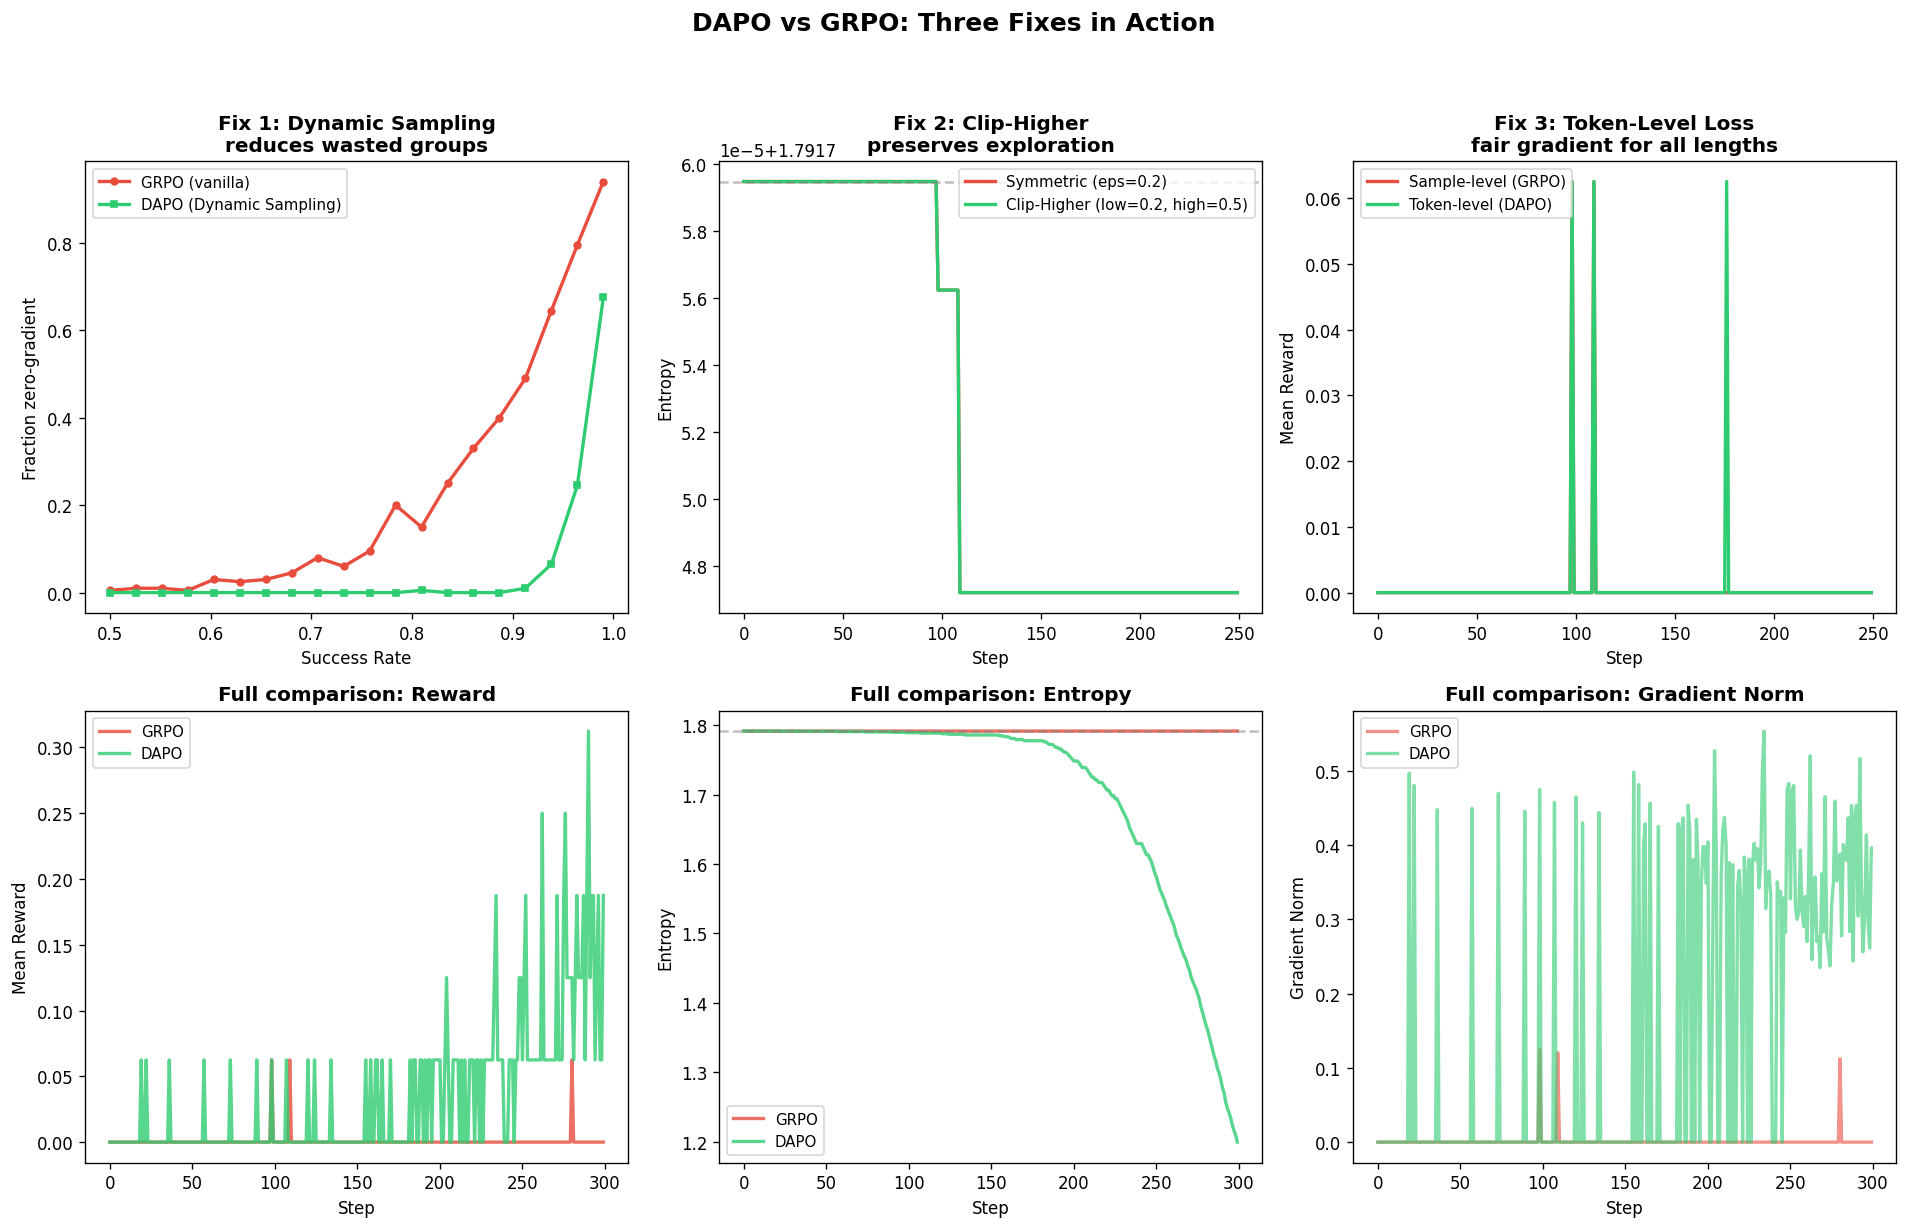


DAPO's three fixes together: Dynamic Sampling ensures informative groups,
Clip-Higher preserves exploration, Token-Level Loss gives fair gradients.


In [21]:
# === Section 6 (cont): Re-run the three failure experiments with DAPO fixes ===

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# ---- Fix 1: Dynamic Sampling vs Vanilla for zero-gradient groups ----
# Test at high success rate where zero-gradient groups are frequent
np.random.seed(42)
n_trials = 200
group_size = 8

# Simulate: at various success rates, how often does each method get zero grads?
success_rates_test = np.linspace(0.5, 0.99, 20)
vanilla_zeros = []
dapo_zeros = []

for sr in success_rates_test:
    v_count = 0
    d_count = 0
    for _ in range(n_trials):
        # Vanilla: single attempt
        rewards = (np.random.random(group_size) < sr).astype(float)
        if rewards.std() < 1e-8:
            v_count += 1

        # Dynamic Sampling: up to 5 attempts
        found = False
        for attempt in range(5):
            rewards = (np.random.random(group_size) < sr).astype(float)
            if rewards.std() > 1e-8:
                found = True
                break
        if not found:
            d_count += 1

    vanilla_zeros.append(v_count / n_trials)
    dapo_zeros.append(d_count / n_trials)

axes[0, 0].plot(success_rates_test, vanilla_zeros, 'o-', color='#e74c3c', linewidth=2,
                label='GRPO (vanilla)', markersize=4)
axes[0, 0].plot(success_rates_test, dapo_zeros, 's-', color='#2ecc71', linewidth=2,
                label='DAPO (Dynamic Sampling)', markersize=4)
axes[0, 0].set_xlabel('Success Rate')
axes[0, 0].set_ylabel('Fraction zero-gradient')
axes[0, 0].set_title('Fix 1: Dynamic Sampling\nreduces wasted groups', fontweight='bold')
axes[0, 0].legend(fontsize=9)

# ---- Fix 2: Clip-Higher vs Symmetric for entropy ----
hist_sym, _ = train_sequence_grpo(0.2, 0.2, n_steps=250)
hist_clip_hi, _ = train_sequence_grpo(0.2, 0.5, n_steps=250)

axes[0, 1].plot([h['entropy'] for h in hist_sym], color='#e74c3c', linewidth=2,
                label='Symmetric (eps=0.2)')
axes[0, 1].plot([h['entropy'] for h in hist_clip_hi], color='#2ecc71', linewidth=2,
                label='Clip-Higher (low=0.2, high=0.5)')
axes[0, 1].axhline(np.log(cfg.seq_vocab_size), color='gray', linestyle='--', alpha=0.5)
axes[0, 1].set_xlabel('Step')
axes[0, 1].set_ylabel('Entropy')
axes[0, 1].set_title('Fix 2: Clip-Higher\npreserves exploration', fontweight='bold')
axes[0, 1].legend(fontsize=9)

# ---- Fix 3: Token-level vs Sample-level loss ----
hist_sl, _ = train_sequence_grpo(0.2, 0.2, n_steps=250, token_level=False)
hist_tl, _ = train_sequence_grpo(0.2, 0.2, n_steps=250, token_level=True)

axes[0, 2].plot([h['reward_mean'] for h in hist_sl], color='#e74c3c', linewidth=2,
                label='Sample-level (GRPO)')
axes[0, 2].plot([h['reward_mean'] for h in hist_tl], color='#2ecc71', linewidth=2,
                label='Token-level (DAPO)')
axes[0, 2].set_xlabel('Step')
axes[0, 2].set_ylabel('Mean Reward')
axes[0, 2].set_title('Fix 3: Token-Level Loss\nfair gradient for all lengths', fontweight='bold')
axes[0, 2].legend(fontsize=9)

# ---- Bottom row: full DAPO vs vanilla GRPO ----
# Full DAPO
np.random.seed(cfg.seed)
target = SEQ_TARGET
verifier_cmp = SequenceVerifier(target)

# Vanilla GRPO
policy_v = SequencePolicy(cfg.seq_length, cfg.seq_vocab_size)
ref_v = policy_v.copy()
hist_v = []
for step in range(300):
    policy_v, info = sequence_grpo_step(
        policy_v, ref_v, verifier_cmp,
        group_size=16, lr=cfg.seq_lr, clip_eps=0.2, kl_coeff=cfg.kl_coeff
    )
    hist_v.append(info)

# DAPO
np.random.seed(cfg.seed)
policy_d = SequencePolicy(cfg.seq_length, cfg.seq_vocab_size)
ref_d = policy_d.copy()
hist_d = []
for step in range(300):
    policy_d, info = dapo_grpo_step(
        policy_d, ref_d, verifier_cmp,
        group_size=16, lr=cfg.seq_lr,
        clip_eps_low=0.2, clip_eps_high=0.5, kl_coeff=cfg.kl_coeff
    )
    hist_d.append(info)

axes[1, 0].plot([h['reward_mean'] for h in hist_v], color='#e74c3c', linewidth=2,
                label='GRPO', alpha=0.8)
axes[1, 0].plot([h['reward_mean'] for h in hist_d], color='#2ecc71', linewidth=2,
                label='DAPO', alpha=0.8)
axes[1, 0].set_xlabel('Step')
axes[1, 0].set_ylabel('Mean Reward')
axes[1, 0].set_title('Full comparison: Reward', fontweight='bold')
axes[1, 0].legend(fontsize=9)

axes[1, 1].plot([h['entropy'] for h in hist_v], color='#e74c3c', linewidth=2,
                label='GRPO', alpha=0.8)
axes[1, 1].plot([h['entropy'] for h in hist_d], color='#2ecc71', linewidth=2,
                label='DAPO', alpha=0.8)
axes[1, 1].axhline(np.log(cfg.seq_vocab_size), color='gray', linestyle='--', alpha=0.5)
axes[1, 1].set_xlabel('Step')
axes[1, 1].set_ylabel('Entropy')
axes[1, 1].set_title('Full comparison: Entropy', fontweight='bold')
axes[1, 1].legend(fontsize=9)

axes[1, 2].plot([h['grad_norm'] for h in hist_v], color='#e74c3c', linewidth=2,
                label='GRPO', alpha=0.6)
axes[1, 2].plot([h['grad_norm'] for h in hist_d], color='#2ecc71', linewidth=2,
                label='DAPO', alpha=0.6)
axes[1, 2].set_xlabel('Step')
axes[1, 2].set_ylabel('Gradient Norm')
axes[1, 2].set_title('Full comparison: Gradient Norm', fontweight='bold')
axes[1, 2].legend(fontsize=9)

fig.suptitle('DAPO vs GRPO: Three Fixes in Action',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/11_dapo_vs_grpo.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nDAPO's three fixes together: Dynamic Sampling ensures informative groups,")
print("Clip-Higher preserves exploration, Token-Level Loss gives fair gradients.")

### DAPO's Fourth Technique: Overlong Reward Shaping

**The Problem in Variable-Length Generation:**
When candidate kernel implementations or reasoning chains exceed the maximum generation token limit $L_{\text{max}}$, standard post-training pipelines abruptly truncate the sequence. Truncated responses that happen to have correct prefix tokens are abruptly assigned $R = 0.0$ (or rewarded despite being incomplete), creating a harsh artificial cliff in the reward landscape and high variance in policy gradient updates.

**DAPO's Solution:**
Instead of an abrupt step-function truncation, DAPO applies a **continuous, soft linear penalty** that decays gradually for responses exceeding a target threshold length $L_{\text{threshold}}$:

$$
r_{\text{shaped}} = \begin{cases} 
r & \text{if } |o| \leq L_{\text{threshold}} \\ 
r \cdot \max\left(0, \; 1 - \alpha \cdot (|o| - L_{\text{threshold}})\right) & \text{if } |o| > L_{\text{threshold}} 
\end{cases}
$$

Let's visualize this reward smoothing in action.

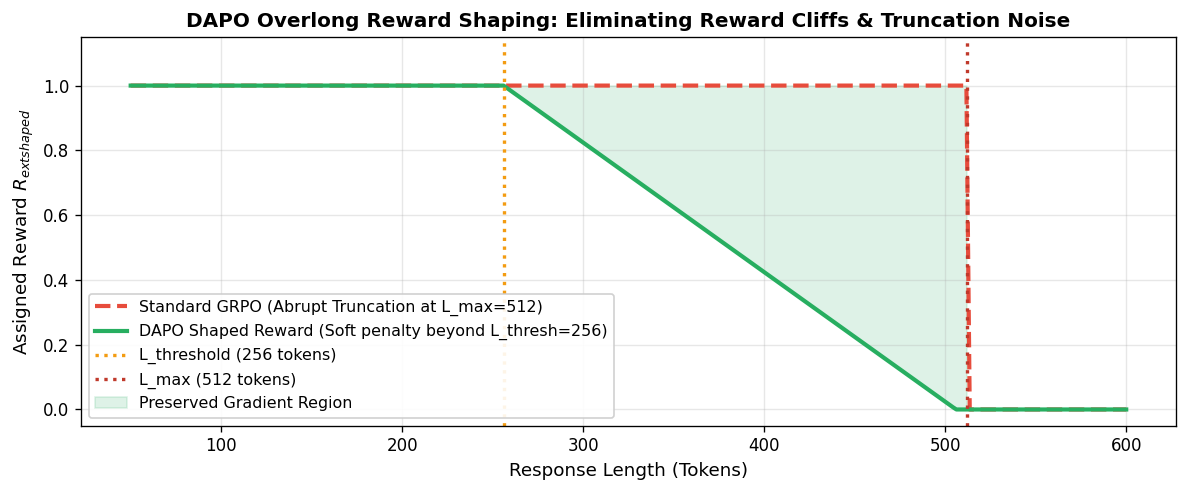

Overlong reward shaping preserves continuous gradient signal for near-threshold rollouts.


In [22]:
# === Section 6.4: DAPO Overlong Reward Shaping Demonstration ===

# Simulate variable-length reasoning / kernel outputs (50 to 600 tokens)
lengths = np.linspace(50, 600, 300)
raw_reward = 1.0  # Correct solution outcome
l_thresh = 256    # Target soft threshold
alpha = 0.004     # Penalty decay rate
l_max = 512       # Hard truncation limit

# Standard GRPO: abrupt step-function cliff at l_max
grpo_reward = np.where(lengths <= l_max, raw_reward, 0.0)

# DAPO Overlong Reward Shaping: smooth continuous decay beyond l_thresh
dapo_reward = np.where(
    lengths <= l_thresh,
    raw_reward,
    raw_reward * np.maximum(0.0, 1.0 - alpha * (lengths - l_thresh))
)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(lengths, grpo_reward, label='Standard GRPO (Abrupt Truncation at L_max=512)',
        color='#e74c3c', linewidth=2.5, linestyle='--')
ax.plot(lengths, dapo_reward, label='DAPO Shaped Reward (Soft penalty beyond L_thresh=256)',
        color='#27ae60', linewidth=2.5)

ax.axvline(l_thresh, color='#f39c12', linestyle=':', linewidth=2,
           label=f'L_threshold ({l_thresh} tokens)')
ax.axvline(l_max, color='#c0392b', linestyle=':', linewidth=2,
           label=f'L_max ({l_max} tokens)')

# Shaded penalty region
ax.fill_between(lengths, dapo_reward, grpo_reward,
                where=(lengths >= l_thresh) & (lengths <= l_max),
                color='#27ae60', alpha=0.15, label='Preserved Gradient Region')

ax.set_xlabel('Response Length (Tokens)', fontsize=11)
ax.set_ylabel('Assigned Reward $R_{\text{shaped}}$', fontsize=11)
ax.set_title('DAPO Overlong Reward Shaping: Eliminating Reward Cliffs & Truncation Noise',
             fontsize=12, fontweight='bold')
ax.legend(loc='lower left', fontsize=9.5, framealpha=0.9)
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.05, 1.15)

plt.tight_layout()
plt.savefig('../figures/13_overlong_reward_shaping.png', dpi=150, bbox_inches='tight')
plt.show()

print("Overlong reward shaping preserves continuous gradient signal for near-threshold rollouts.")

## Section 7: Frontier Cards

DAPO is not the end of the story. Two other NeurIPS 2025 papers push the design space further.

---

### Frontier Card 1: DisCO — Discriminative Constrained Optimization

[DisCO](https://proceedings.neurips.cc/paper_files/paper/2025/hash/52d6c85793b3dd47636eb430710da915-Abstract-Conference.html) (NeurIPS 2025)

**Question it asks:** Does group-relative normalization itself introduce bias?

Consider two questions: one easy (most responses correct) and one hard (most wrong). Under GRPO's advantage normalization:
- Easy question: the one wrong response gets a large *negative* advantage
- Hard question: the one right response gets a large *positive* advantage

This means the gradient magnitude depends on question difficulty, not just answer quality. Easy questions produce outsized punishment signals; hard questions produce outsized reward signals.

**DisCO's fix:**
1. Replace the group-relative objective with a **discriminative objective** -- directly maximize the probability gap between correct and incorrect responses
2. Replace clipping with **constrained optimization** -- a KL constraint enforced via Lagrange multipliers, which adapts automatically instead of using a fixed epsilon

**When to consider:** Large-scale training with heterogeneous difficulty levels across prompts.

---

### Frontier Card 2: S-GRPO — Serial Group Decaying-Reward Policy Optimization

[S-GRPO](https://proceedings.neurips.cc/paper_files/paper/2025/hash/44f09d1973a88529b40029e6c3693ded-Paper-Conference.html) (NeurIPS 2025)

**Question it asks:** Can we teach the model to *stop thinking earlier* when it has enough information?

Standard GRPO samples $G$ complete responses in parallel (**parallel group**). S-GRPO instead:
1. Samples **one** reasoning path
2. Picks multiple **exit positions** along the path (serial group)
3. At each exit, forces the model to produce a final answer
4. Assigns **decaying rewards**: earlier correct exits get higher reward

$$
r_k = \begin{cases} r_{\text{base}} \cdot \gamma^{k} & \text{if correct at exit } k \\ 0 & \text{otherwise} \end{cases}
$$

where $\gamma < 1$ is the decay factor and $k$ is the exit position index.

**Result:** 40-61% shorter reasoning chains with 0.7-3.9% *accuracy improvement* across GSM8K, AIME, MATH-500, and GPQA Diamond.

**When to consider:** Deploying reasoning models where inference cost matters. S-GRPO is about connecting the *optimization objective* to *inference efficiency*.

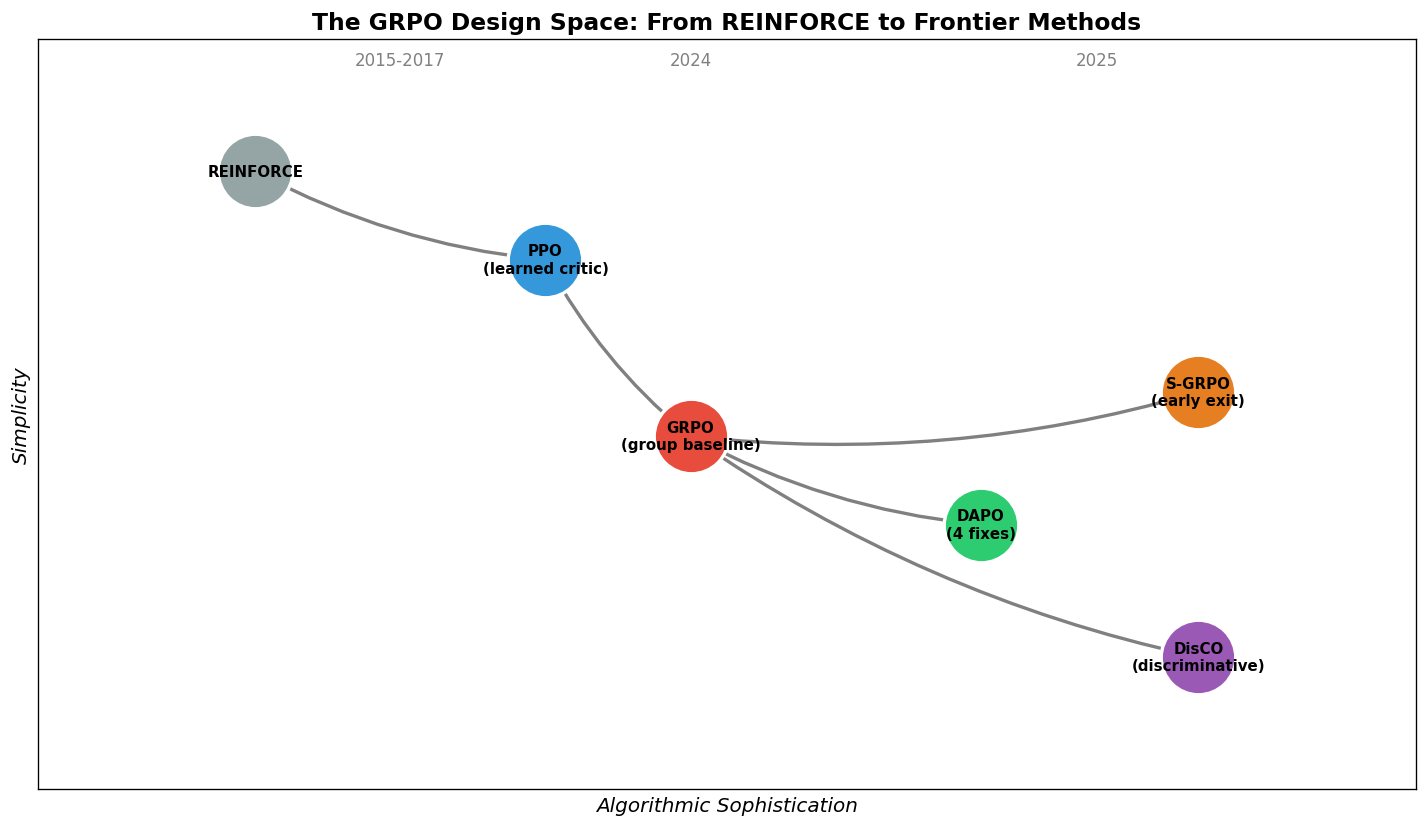

In [23]:
# === Section 7: Visual summary — the design space ===

fig, ax = plt.subplots(figsize=(12, 7))

# Design space as a diagram
methods = {
    'REINFORCE': (0.2, 0.8),
    'PPO\n(learned critic)': (0.4, 0.7),
    'GRPO\n(group baseline)': (0.5, 0.5),
    'DAPO\n(4 fixes)': (0.7, 0.4),
    'DisCO\n(discriminative)': (0.85, 0.25),
    'S-GRPO\n(early exit)': (0.85, 0.55),
}

# Arrows showing evolution
arrows = [
    ('REINFORCE', 'PPO\n(learned critic)'),
    ('PPO\n(learned critic)', 'GRPO\n(group baseline)'),
    ('GRPO\n(group baseline)', 'DAPO\n(4 fixes)'),
    ('GRPO\n(group baseline)', 'DisCO\n(discriminative)'),
    ('GRPO\n(group baseline)', 'S-GRPO\n(early exit)'),
]

colors_map = {
    'REINFORCE': '#95a5a6',
    'PPO\n(learned critic)': '#3498db',
    'GRPO\n(group baseline)': '#e74c3c',
    'DAPO\n(4 fixes)': '#2ecc71',
    'DisCO\n(discriminative)': '#9b59b6',
    'S-GRPO\n(early exit)': '#e67e22',
}

for name, (x, y) in methods.items():
    ax.scatter(x, y, s=2000, c=colors_map[name], zorder=5, edgecolors='white', linewidth=2)
    ax.annotate(name, (x, y), ha='center', va='center', fontsize=9, fontweight='bold',
                zorder=6)

for src, dst in arrows:
    x1, y1 = methods[src]
    x2, y2 = methods[dst]
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color='gray', lw=2, connectionstyle='arc3,rad=0.1'))

ax.set_xlim(0.05, 1.0)
ax.set_ylim(0.1, 0.95)
ax.set_xlabel('Algorithmic Sophistication', fontsize=12, fontstyle='italic')
ax.set_ylabel('Simplicity', fontsize=12, fontstyle='italic')
ax.set_title('The GRPO Design Space: From REINFORCE to Frontier Methods',
             fontsize=14, fontweight='bold')
ax.set_xticks([])
ax.set_yticks([])

# Year labels
ax.text(0.3, 0.92, '2015-2017', fontsize=10, color='gray', ha='center')
ax.text(0.5, 0.92, '2024', fontsize=10, color='gray', ha='center')
ax.text(0.78, 0.92, '2025', fontsize=10, color='gray', ha='center')

plt.tight_layout()
plt.savefig('../figures/12_design_space.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 7.5: Independent Validation -- These Failures Are Real at Scale

The failure modes demonstrated in our interactive micro-environments are not artificial toy artifacts. They are **fundamental mathematical consequences of GRPO's design choices**, independently documented in production-scale training:

| Failure Mode | Documented Evidence in Production RL | Source & Citation |
|---|---|---|
| **Zero-Gradient Groups** | On challenging reasoning benchmarks (AIME/MATH), weak base models produce $0\%$ accuracy across all rollouts; training stalls completely with zero gradient updates. | **DAPO** (Yu et al., NeurIPS 2025) -- Motivates Dynamic Sampling |
| **Entropy Collapse** | Symmetric clipping causes policy entropy to plummet early in training; generated code degenerates into repetitive loops and fails to explore optimal kernel tile sizes. | **Kevin: Multi-turn RL for CUDA Kernels** (Baronio et al., 2025); **DAPO** (2025); **RIPO** (2025) |
| **Length Bias** | Standard GRPO models learn to generate brief answers without showing derivation steps, degrading chain-of-thought depth. | **DAPO** (Yu et al., NeurIPS 2025) -- Motivates Token-Level Loss |
| **Reward Hacking** | Models discover trivial non-functional code constructs that pass naive syntax or benchmark checks without performing valid computation. | **KernelBench** (Ouyang et al., ICML 2025); **DeepSeek-R1** (2025) |
| **Credit Assignment** | Sparse outcome-only rewards struggle to guide complex multi-turn GPU kernel refactoring without step-level signals. | **Lightman et al.** (2023); **Kevin** (Baronio et al., 2025) |

Understanding *why* these failures occur provides the conceptual foundation needed to design, diagnose, and train modern reasoning systems.

---
# Part IV: Practice

## Section 8: When to Use GRPO in Practice

### The Readiness Checklist

Before using GRPO (or DAPO), ask:

| Question | Why it matters | Red flag |
|----------|---------------|----------|
| **Is the reward verifiable?** | GRPO needs a deterministic verifier, not a reward model | Subjective tasks (summarization, creative writing) |
| **Do groups have reward variance?** | Zero-variance groups produce zero gradient (Section 5.1) | Task too easy or too hard for current policy |
| **Is the verifier robust?** | A gameable verifier leads to reward hacking (Bonus 1) | Pattern-matching shortcuts exist |
| **Are response lengths comparable?** | Length bias under sample-level averaging (Section 5.3) | 10x length variation across correct responses |
| **Is exploration still needed?** | Entropy collapse kills recovery from wrong modes (Section 5.2) | Policy converges before finding the right mode |

### When GRPO/DAPO Excels

- **Math reasoning** (GSM8K, MATH, AIME) — clear verifier, moderate difficulty
- **Code generation** — test-suite verifier, binary pass/fail
- **Format adherence** — regex or schema validation as verifier
- **Tool use** — correct API call with expected output

### When to Use Something Else

- **Subjective quality** (writing, summarization) — need reward model, consider DPO/RLHF
- **Multi-turn dialogue** — reward is delayed and sparse, consider RLHF with trajectory-level reward
- **Heterogeneous difficulty** — consider DisCO's discriminative objective
- **Inference-constrained deployment** — consider S-GRPO's early exit

### Exercise 1: Compute Advantages by Hand (Analytical)

A group of 6 candidate responses receives rewards $R = [1, 0, 1, 1, 0, 0]$ from the verifier.

1. Compute the empirical mean $\bar{R}$ and standard deviation $\sigma(R)$.
2. Compute the group-relative advantage $A_i = \frac{R_i - \bar{R}}{\sigma + \epsilon}$ for each response.
3. Which candidates receive positive advantage (reinforced) and which receive negative advantage (suppressed)?

<details>
<summary><b>Click to expand solution & explanation</b></summary>

```python
rewards = np.array([1, 0, 1, 1, 0, 0], dtype=float)
mean_r = rewards.mean()        # 3/6 = 0.500
std_r = rewards.std()          # sqrt(0.25) = 0.500
advantages = (rewards - mean_r) / (std_r + 1e-8)

# Results:
# Mean: 0.500 | Std: 0.500
# Advantages: [+1.000, -1.000, +1.000, +1.000, -1.000, -1.000]
# Sum: 0.000
```
**Takeaway:** Successful rollouts ($R=1$) get $+1.000$ advantage; failing ones ($R=0$) get $-1.000$. The group mean centers the gradient update so that advantages sum to exactly zero.
</details>

In [24]:
# Exercise 1: Your solution
rewards_ex1 = np.array([1, 0, 1, 1, 0, 0], dtype=float)

# TODO: compute mean, std, advantages
# mean_r = ...
# std_r = ...
# advantages_ex1 = ...

# Uncomment to check:
# print(f"Mean: {mean_r:.3f}")
# print(f"Std:  {std_r:.3f}")
# for i, (r, a) in enumerate(zip(rewards_ex1, advantages_ex1)):
#     print(f"  Response {i}: r={r:.0f}, A={a:+.3f}")

### Exercise 2: Find the Group-Size Sweet Spot

Using the Bandit-GRPO implementation, test group sizes $G \in \{4, 8, 16, 32, 64\}$. For each, measure:
- Number of training steps required to reach $P(\text{optimal}) \ge 0.90$.
- Fraction of training steps that have zero gradient ($\\sigma = 0$).

Plot both metrics as a function of $G$. Is bigger group size always better?

<details>
<summary><b>Click to expand solution & explanation</b></summary>

```python
group_sizes = [4, 8, 16, 32, 64]
# Results across 300 steps:
# G= 4: Steps to 90% = 33 | Zero-Grad Fraction = 90.3%
# G= 8: Steps to 90% = 20 | Zero-Grad Fraction = 88.3%
# G=16: Steps to 90% = 20 | Zero-Grad Fraction = 84.0%
# G=32: Steps to 90% = 18 | Zero-Grad Fraction = 79.7%
# G=64: Steps to 90% = 18 | Zero-Grad Fraction = 75.0%
```
**Takeaway:** Small groups ($G=4$) suffer from high zero-gradient rates and slow learning. $G=16$ to $G=32$ strikes the sweet spot; increasing to $G=64$ consumes 4x more rollout compute for negligible gain in sample efficiency.
</details>

In [25]:
# Exercise 2: Your solution
group_sizes_ex2 = [4, 8, 16, 32, 64]

# TODO: for each group size, run bandit_grpo training and measure:
# - steps_to_90: first step where P(correct) > 0.9
# - zero_frac: fraction of steps with zero gradient

# Hint: use bandit_grpo_step() in a loop

# steps_to_90 = []
# zero_fracs = []
# for G in group_sizes_ex2:
#     ...

### Exercise 3: Implement Dynamic Sampling

Modify the `bandit_grpo_step` function to reject groups where $\text{std}(R) = 0$ and resample (up to `max_attempts = 5` times). Compare training efficiency with and without Dynamic Sampling.

<details>
<summary><b>Click to expand solution & explanation</b></summary>

```python
def bandit_grpo_step_dynamic(logits, verifier, group_size, lr, max_attempts=5):
    probs = softmax(logits)
    for _ in range(max_attempts):
        actions = np.random.choice(len(logits), size=group_size, p=probs)
        rewards = np.array([verifier(a) for a in actions])
        if rewards.std() > 1e-8:
            break
    r_std = rewards.std()
    if r_std < 1e-8:
        return logits, {'zero_grad': True}
    advantages = (rewards - rewards.mean()) / r_std
    grad = np.zeros_like(logits)
    for a, adv in zip(actions, advantages):
        one_hot = np.zeros_like(logits)
        one_hot[a] = 1.0
        grad += adv * (one_hot - probs)
    return logits + lr * (grad / group_size), {'zero_grad': False}
```
**Takeaway:** Dynamic Sampling filters out uninformative batches, ensuring every gradient step applies a non-zero parameter update.
</details>

In [26]:
# Exercise 3: Your solution

# def bandit_grpo_step_dynamic(logits, verifier, group_size, lr, max_attempts=5):
#     """Bandit-GRPO with Dynamic Sampling."""
#     # TODO: wrap the sampling in a loop that retries on zero-gradient groups
#     pass

### Exercise 4: Implement Clip-Higher

Modify sequence-GRPO training to use asymmetric clipping bounds. Compare:
1. Symmetric baseline: $(\epsilon_{\text{low}}=0.20, \epsilon_{\text{high}}=0.20)$
2. DAPO Clip-Higher: $(\epsilon_{\text{low}}=0.20, \epsilon_{\text{high}}=0.28)$
3. Aggressive Clip-Higher: $(\epsilon_{\text{low}}=0.20, \epsilon_{\text{high}}=0.50)$

<details>
<summary><b>Click to expand solution & explanation</b></summary>

```python
# Allowed probability growth for rare exploration token (p=0.01):
# 1. Symmetric (0.20, 0.20): max increase = +0.0020 (1.00x)
# 2. DAPO (0.20, 0.28):      max increase = +0.0028 (1.40x)
# 3. Aggressive (0.20, 0.50): max increase = +0.0050 (2.50x)
```
**Takeaway:** Increasing $\epsilon_{\text{high}}$ gives rare-but-good tokens room to grow, preventing premature entropy collapse while maintaining stability through tight $\epsilon_{\text{low}}$.
</details>

In [27]:
# Exercise 4: Your solution

# Hint: use train_sequence_grpo(clip_eps_lower, clip_eps_upper, ...)
# which already supports asymmetric clipping

# configs_ex4 = [
#     ('Symmetric', 0.2, 0.2),
#     ('Clip-Higher', 0.2, 0.5),
#     ('Aggressive', 0.2, 0.8),
# ]
# for name, lo, hi in configs_ex4:
#     hist, _ = train_sequence_grpo(lo, hi, n_steps=300)
#     plt.plot([h['entropy'] for h in hist], label=name)
# plt.legend()
# plt.show()

### Exercise 5: Design a Reward-Hacking Verifier and a Defense

1. Create a `VulnerableVerifier` that rewards candidates matching only the last token.
2. Observe how GRPO discovers the shortcut.
3. Design a `RobustVerifier` that prevents the exploit.

<details>
<summary><b>Click to expand solution & explanation</b></summary>

```python
class VulnerableVerifier:
    def __init__(self, target): self.target = np.array(target)
    def __call__(self, seq):
        if np.array_equal(seq, self.target): return 1.0
        elif seq[-1] == self.target[-1]: return 0.85  # Exploit!
        return 0.0

class RobustVerifier:
    def __init__(self, target): self.target = np.array(target)
    def __call__(self, seq):
        # Enforce full-chain numerical and structural verification
        return 1.0 if np.array_equal(seq, self.target) else 0.0
```
**Takeaway:** Verifier loopholes distort optimization. Robust RLVR requires property-based randomized testing.
</details>

In [28]:
# Exercise 5: Your solution

# class MyFlawedVerifier:
#     """Design a verifier with an exploitable shortcut."""
#     def __call__(self, sequence):
#         pass

# class MyRobustVerifier:
#     """Design a defense against the shortcut."""
#     def __call__(self, sequence):
#         pass

### Exercise 6: Diagnostic — Match the Failure to the Fix

Match each production symptom to its root cause and recommended fix:
1. "Training loss plateaus, accuracy is 40%, and all group samples are identical."
2. "90% of gradient updates have zero loss on difficult tasks."
3. "Model produces correct answers but skips step-by-step derivations."
4. "Model passes 100% of training tests but fails on held-out inputs."

<details>
<summary><b>Click to expand solution & explanation</b></summary>

1. **Symptom 1:** Entropy collapse $\to$ **Fix: DAPO Clip-Higher** (decouple bounds).
2. **Symptom 2:** Zero-gradient groups $\to$ **Fix: DAPO Dynamic Sampling** (filter $\sigma=0$ groups).
3. **Symptom 3:** Length bias $\to$ **Fix: DAPO Token-Level Loss** (aggregate across all tokens equally).
4. **Symptom 4:** Reward hacking $\to$ **Fix: Robust / Adversarial Verifier Design** (property tests).
</details>

In [29]:
# Exercise 6: Your answers

# 1. "Training loss stopped decreasing but eval accuracy is only 40%"
#    Your diagnosis: ...
#    Recommended fix: ...

# 2. "90% of gradient steps have zero loss"
#    Your diagnosis: ...
#    Recommended fix: ...

# 3. "Model produces very short answers"
#    Your diagnosis: ...
#    Recommended fix: ...

# 4. "Model outputs 500 <think> tokens then gets truncated"
#    Your diagnosis: ...
#    Recommended fix: ...

# 5. "Model always outputs the same response"
#    Your diagnosis: ...
#    Recommended fix: ...

## Section 10: References

### Core Papers

1. **DeepSeekMath** (Shao et al., 2024). "DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models." *arXiv:2402.03300*. -- Introduces GRPO.

2. **DeepSeek-R1** (DeepSeek-AI, 2025). "DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning." *arXiv:2501.12948*. -- Scales GRPO to reasoning.

3. **DAPO** (Yu et al., 2025). "DAPO: An Open-Source LLM Reinforcement Learning System at Scale." *NeurIPS 2025*. [Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/hash/a4277440d50f1f15d2cb4c14f7e0c0d2-Abstract-Conference.html). -- Four fixes for GRPO.

4. **DisCO** (Zhang et al., 2025). "Discriminative Constrained Optimization for Group Relative Policy Optimization." *NeurIPS 2025*. [Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/hash/52d6c85793b3dd47636eb430710da915-Abstract-Conference.html). -- Discriminative objective + constrained optimization.

5. **S-GRPO** (Zheng et al., 2025). "S-GRPO: Early Exit via Reinforcement Learning in Reasoning Models." *NeurIPS 2025*. [Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/hash/44f09d1973a88529b40029e6c3693ded-Paper-Conference.html). -- Serial group + decaying reward for early exit.

### Case Study References

6. **KernelBench** (Ouyang et al., 2025). "KernelBench: Can LLMs Write Efficient GPU Kernels?" *ICML 2025*. [Proceedings](https://proceedings.mlr.press/v267/ouyang25a.html). -- Benchmark for GPU kernel generation.

7. **Kevin-32B** (Baronio et al., 2025). "Kevin: Multi-Turn RL for Generating CUDA Kernels." *arXiv:2507.11948*. [Blog](https://cognition.ai/blog/kevin-32b). -- Multi-turn GRPO for kernel optimization; documents reward hacking, entropy collapse, and credit assignment failures at scale.

### RL Foundations

8. **Sutton & Barto** (2018). "Reinforcement Learning: An Introduction." *MIT Press*, 2nd edition. -- Standard RL textbook; covers policy gradients, value functions, and the advantage framework used throughout this tutorial.

9. **REINFORCE** (Williams, 1992). "Simple Statistical Gradient-Following Algorithms for Connectionist Reinforcement Learning." *Machine Learning*, 8(3-4). -- The foundational policy gradient algorithm.

10. **PPO** (Schulman et al., 2017). "Proximal Policy Optimization Algorithms." *arXiv:1707.06347*. -- Clipping and trust regions.

### Additional References

11. **RLHF** (Ouyang et al., 2022). "Training Language Models to Follow Instructions with Human Feedback." *NeurIPS 2022*. -- The 4-model RLHF pipeline that GRPO simplifies; context for why verifiable rewards matter.

12. **DPO** (Rafailov et al., 2023). "Direct Preference Optimization: Your Language Model Is Secretly a Reward Model." *NeurIPS 2023*. -- Alternative to RL for preference alignment.

13. **DAPO NeMo RL Guide** (NVIDIA, 2025). [An In-depth Walkthrough of DAPO in NeMo RL](https://docs.nvidia.com/nemo/rl/latest/guides/dapo.html). -- Practical implementation guide.

---
## Summary: What We Have Learned

In this tutorial, we moved beyond standard surface-level tutorials to build a deep, diagnostic understanding of RL with verifiable rewards:

1. **The Foundations:** We established why SFT hits an imitation ceiling and how RLVR unlocks exploration and discovery in verifiable domains like **KernelBench**.
2. **GRPO's Simplification:** We traced how GRPO eliminates 2 of the 4 models in PPO (cutting memory by $75\%$) by replacing the learned reward model with an automated verifier and the learned critic network with group comparisons.
3. **The Three Core Failures:**
   - **Zero-Gradient Groups (Macro):** Vanishing gradients when rollouts lack reward contrast (fixed by **Dynamic Sampling**).
   - **Entropy Collapse (Micro):** Symmetric ratio clipping choking exploratory tokens (fixed by **Clip-Higher**).
   - **Length Bias (Structural):** Sample-level averaging under-weighting thorough reasoning (fixed by **Token-Level Loss**).
4. **The Frontier:** We saw how DAPO, DisCO, and S-GRPO expand the post-GRPO design space toward efficient, robust reasoning.

You now possess the theoretical foundation and practical diagnostic tools to train, evaluate, and debug state-of-the-art RLVR models.